# Análisis exploratorio del dataset de partidas de League of Legends

**Entrega 2 · Proyecto Integrador de Ciencia de Datos · UTN FRM · 2026**
Comisión 5K09 · Grupo 5K09-02

> **Pregunta del proyecto:** ¿Es posible predecir la duración de una partida de
> League of Legends a partir de las características de los jugadores, de los
> campeones de los equipos y las condiciones iniciales de la partida?

Este notebook recorre el dataset que produjo el DAG `lol_ingest` de la Unidad 1
siguiendo **las mismas seis fases que define la teórica**, en el mismo orden:
inspección inicial, análisis univariado, análisis bivariado, análisis de
calidad, análisis temporal y generación de hipótesis. Después resuelve **ocho
fichas de hipótesis** con las seis casillas del TP2 y termina en la **tabla de
columnas candidatas**, que es el entregable que se lleva la Entrega 3.

Se corre de arriba hacia abajo. El dataset viaja con el notebook, en
`datos/`, así que no hace falta levantar Airflow para reproducirlo.

# Sección 0 · Qué cambió desde la Entrega 1

Nada. El docente no marcó correcciones sobre el pipeline, y ni la pregunta del
proyecto ni el esquema cambiaron: el dataset que se analiza acá es exactamente
el que se presentó el 9 de septiembre, producido por la corrida del 5–6 de
septiembre. Los dos cambios que figuran en el historial del repo —la rotación
de claves por *owner key* y la quita de `count_smite` por varianza cero— son
anteriores a la entrega y ya estaban defendidos en ella.

Lo único nuevo es de acá para adelante: hasta ahora sabíamos que el dataset se
producía solo; todavía no sabíamos qué tenía adentro.

# Sección 1 · Inspección inicial del dataset

El objetivo de esta fase es armarse un mapa mental del dataset antes de
calcular nada: cuántas filas hay, qué es una fila, cómo se llaman las columnas
y de qué tipo son.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Los dos colores de la cátedra, y nada más
TEAL, LADRILLO = "#009086", "#B5402C"

POS = ["top", "jng", "mid", "bot", "sup"]
EQUIPOS = ["t1", "t2"]

carpeta = Path("datos") if Path("datos").is_dir() else Path("notebooks/entrega-2/datos")
CSV = sorted(carpeta.glob("lol_*.csv"))[-1]
df = pd.read_csv(CSV)
CSV.name

'lol_2026-09-06.csv'

### Dimensiones, y qué es una fila

In [2]:
# Observaciones y variables
df.shape

(19145, 137)

**Una fila es una partida clasificatoria de cola 420 (solo/dúo) de la Season
16.** 19.145 partidas, 137 columnas. La clave primaria es `match_id`, y trae el
prefijo de la plataforma adentro: `LA2_1595380842`.

Es la unidad de análisis que pide la pregunta del proyecto, y coincide: se
quiere predecir la duración *de una partida*, así que una fila es una partida.
La columna objetivo es `game_duration_s`, en segundos, y es **continua**: el
problema de la Unidad 3 es de **regresión**, no de clasificación.

### Ciento treinta y siete columnas no se leen de a una

El dataset es **ancho a propósito**: los diez jugadores de la partida están
aplanados en columnas en vez de ocupar diez filas. Por eso el ancho no se lee
como una lista de 137 nombres sino como tres bloques con un patrón de nombre
fijo.

In [3]:
# Las familias de columnas, según el primer segmento del nombre
df.columns.str.split("_").str[0].value_counts()

t1       67
t2       67
match     1
game      1
roles     1
Name: count, dtype: int64

In [4]:
# La aritmética del ancho: tres bloques, y de dónde sale cada número
pd.DataFrame(
    [("A · identidad, objetivo y calidad", 3,
      "match_id, game_duration_s, roles_inferidos"),
     ("B · una fila de jugador aplanada", 100,
      "10 features x 5 posiciones x 2 equipos"),
     ("C · agregados de equipo", 34,
      "17 agregados x 2 equipos")],
    columns=["bloque", "columnas", "cómo se arma"]).set_index("bloque")

,columnas,cómo se arma
bloque,,
"A · identidad, objetivo y calidad",3,"match_id, game_duration_s, roles_inferidos"
B · una fila de jugador aplanada,100,10 features x 5 posiciones x 2 equipos
C · agregados de equipo,34,17 agregados x 2 equipos


In [5]:
# Las 10 features que se repiten por jugador, con el sufijo tal como aparece
[c.replace("t1_top_", "") for c in df.columns if c.startswith("t1_top_")]

['champ_id',
 'champ_name',
 'sum1',
 'sum2',
 'rune_primary',
 'rune_sub',
 'player_elo',
 'player_winrate',
 'champ_mastery_pts',
 'is_main']

El nombre de cada columna del bloque B es `{t1|t2}_{top|jng|mid|bot|sup}_{feature}`,
y el del bloque C es `{t1|t2}_{agregado}`. `t1` es el equipo con `teamId` 100 y
`t2` el 200, que es un rótulo arbitrario que asigna Riot — eso va a importar en
la hipótesis H8.

### Tipos de datos

In [6]:
# Cuántas columnas hay de cada tipo
df.dtypes.value_counts()

int64      106
float64     20
str         11
Name: count, dtype: int64

Ninguna numérica quedó como texto: las 11 columnas `str` son `match_id` y los
10 `champ_name`, y son las únicas que tienen que ser texto. El `str` en vez de
`object` es de pandas 3, que le da dtype propio a las columnas de cadenas.

Pero el conteo esconde algo que sí importa, y es lo contrario: **hay columnas
que son enteras sin ser cantidades.** `champ_id`, `sum1`, `sum2`,
`rune_primary` y `rune_sub` son códigos que Riot usa para nombrar cosas, no
números que se puedan sumar ni ordenar.

In [7]:
# Los valores que toma un código: son etiquetas, no magnitudes
df["t1_mid_rune_primary"].value_counts().sort_index()

t1_mid_rune_primary
8000    4104
8100    7275
8200    5994
8300    1383
8400     389
Name: count, dtype: int64

Que el estilo de runa 8300 tenga un número mayor que el 8000 no significa que
sea *más* de algo. Si esa columna entra a un modelo tal como está, el modelo va
a interpretar una distancia donde sólo hay una etiqueta. Es una decisión
pendiente que se resuelve en la tabla de candidatas de la Sección 9.

Los cuatro tipos de variable, sobre este dataset:

| Tipo | Columnas | Ejemplo |
|---|---|---|
| Numérica continua | objetivo, `player_winrate`, los cinco `avg_*` | `t1_avg_attackrange` |
| Numérica de conteo | `num_*`, `count_*`, `mains_count`, `champ_mastery_pts`, `player_elo` | `t1_num_tanks` |
| **Nominal codificada como entero** | `champ_id`, `sum1`, `sum2`, `rune_primary`, `rune_sub` | `t1_mid_champ_id` |
| Categórica de texto | los 10 `champ_name` | `t1_mid_champ_name` |
| Identificador | `match_id` | — |

### Formato y estructura: dónde el dataset se aparta de tidy

Tidy significa cada fila una observación y cada columna una variable. Acá la
fila es una partida, y eso está bien, pero *«el elo del jugador»* no es una
columna: son veinte. El dataset guarda diez jugadores aplanados a lo ancho.

Es una **concesión deliberada**, no un descuido. La alternativa —diez filas por
partida— rompería la clave primaria y obligaría a agregar en cada consulta, y
la pregunta del proyecto es sobre partidas, no sobre jugadores. Se declara y se
defiende: el precio es que cualquier análisis sobre jugadores necesita
desapilar primero, que es lo que hace la celda de abajo cuando hace falta.

In [8]:
# El bloque de jugador, desapilado: 191.450 jugadores para mirar distribuciones
def por_jugador(feature):
    """Las 10 columnas de una feature de jugador, apiladas en una sola Serie."""
    cols = [f"{e}_{p}_{feature}" for e in EQUIPOS for p in POS]
    return pd.Series(df[cols].to_numpy().ravel(), name=feature)


por_jugador("player_elo").describe().round(0)

count    191450.0
mean       2502.0
std         856.0
min         800.0
25%        1782.0
50%        2557.0
75%        3154.0
max        5571.0
Name: player_elo, dtype: float64

### La plataforma está escondida en la clave

El prefijo de `match_id` dice en qué servidor se jugó la partida. No es una
columna del esquema, pero se deriva en una línea y va a hacer falta: es la
única variable de contexto que tiene el dataset.

In [9]:
# Todas las derivadas del análisis, de una vez (y así no se fragmenta el frame)
elo_cols = [f"{e}_{p}_player_elo" for e in EQUIPOS for p in POS]
wr_cols = [f"{e}_{p}_player_winrate" for e in EQUIPOS for p in POS]
mas_cols = [f"{e}_{p}_champ_mastery_pts" for e in EQUIPOS for p in POS]

elo_t1 = df[[f"t1_{p}_player_elo" for p in POS]].mean(axis=1)
elo_t2 = df[[f"t2_{p}_player_elo" for p in POS]].mean(axis=1)
imputados = ((df[elo_cols].to_numpy() == 1500)
             & (df[wr_cols].to_numpy() == 0.50)).sum(axis=1)

derivadas = pd.DataFrame({
    "plataforma": df["match_id"].str.split("_").str[0],
    "duracion_min": df["game_duration_s"] / 60,
    "elo_partida": df[elo_cols].mean(axis=1),
    "wr_partida": df[wr_cols].mean(axis=1),
    "desbalance_elo": (elo_t1 - elo_t2).abs(),
    "mastery_partida": df[mas_cols].mean(axis=1),
    "logmastery_partida": np.log1p(df[mas_cols]).mean(axis=1),
    "mains_total": df["t1_mains_count"] + df["t2_mains_count"],
    "jugadores_imputados": imputados,
    "tanques_total": df["t1_num_tanks"] + df["t2_num_tanks"],
    "magos_total": df["t1_num_mages"] + df["t2_num_mages"],
    "flash_total": df["t1_count_flash"] + df["t2_count_flash"],
    "alcance_medio": (df["t1_avg_attackrange"] + df["t2_avg_attackrange"]) / 2,
    "defensa_media": (df["t1_avg_defense"] + df["t2_avg_defense"]) / 2,
    "magia_media": (df["t1_avg_magic"] + df["t2_avg_magic"]) / 2,
    "armadura_total": df["t1_total_base_armor"] + df["t2_total_base_armor"],
    "hp_total": df["t1_total_base_hp"] + df["t2_total_base_hp"]})

df = pd.concat([df, derivadas], axis=1)
ORIGINALES = [c for c in df.columns if c not in derivadas.columns]
dur = df["game_duration_s"]
derivadas.columns.tolist()

['plataforma',
 'duracion_min',
 'elo_partida',
 'wr_partida',
 'desbalance_elo',
 'mastery_partida',
 'logmastery_partida',
 'mains_total',
 'jugadores_imputados',
 'tanques_total',
 'magos_total',
 'flash_total',
 'alcance_medio',
 'defensa_media',
 'magia_media',
 'armadura_total',
 'hp_total']

In [10]:
# Cuántas partidas trajo cada servidor
df["plataforma"].value_counts()

plataforma
KR      3430
LA1     3355
BR1     3333
LA2     3066
NA1     3011
EUW1    2950
Name: count, dtype: int64

Seis servidores, entre 2.950 y 3.430 partidas cada uno. El reparto es parejo
porque el DAG lo impone: reparte la cuota de descarga entre las seis
plataformas. **No es una muestra representativa de League of Legends**, y eso
está analizado aparte en `docs/informe-sesgo-muestreo.html`: los servidores
tienen niveles de juego distintos, así que el servidor es una tercera variable
candidata a contaminar cualquier medida — y en la H1 va a hacer exactamente
eso.

# Sección 2 · Análisis univariado

El objetivo de esta fase es mirar cada variable por separado para detectar
comportamientos atípicos antes de cruzar nada. Empezamos por la única columna
que no se puede mirar por encima.

### La columna objetivo, que es el número más importante de la entrega

In [11]:
# El objetivo: centro, dispersión y colas
dur.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(1)

count    19145.0
mean      1748.0
std        424.3
min        301.0
1%         724.9
5%         955.0
25%       1496.0
50%       1751.0
75%       2010.0
95%       2432.8
99%       2778.6
max       3963.0
Name: game_duration_s, dtype: float64

In [12]:
# Las medidas de forma del objetivo
pd.Series({"asimetría": dur.skew(), "curtosis": dur.kurt()}).round(3)

asimetría   -0.039
curtosis     0.579
dtype: float64

**Éste es el hallazgo más inesperado del perfil.** La duración tiene asimetría
−0,039 y curtosis 0,579: es prácticamente simétrica, con colas apenas más
gordas que una normal. Media 1.748 segundos y mediana 1.751 — casi el mismo
número, que es la firma de una distribución sin cola dominante.

Importa porque contradice lo que uno esperaría de una variable de tiempo: los
tiempos de espera, los montos y las duraciones casi siempre tienen cola
derecha larga y piden logaritmo. Ésta no. **El objetivo no necesita
transformarse**, y eso hay que saber decirlo en la defensa con el número.

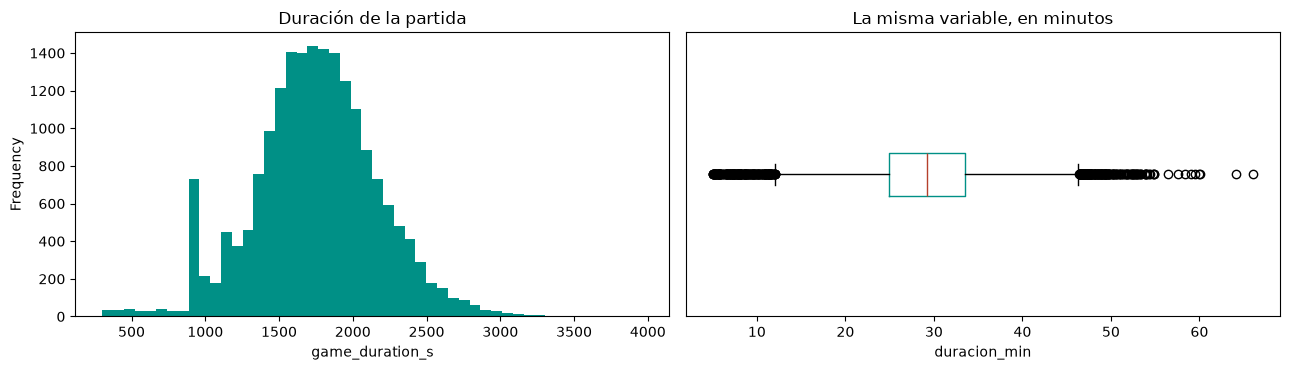

In [13]:
# La distribución del objetivo, y el mismo histograma en minutos
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
dur.plot.hist(bins=50, color=TEAL, ax=axes[0])
axes[0].set_title("Duración de la partida")
axes[0].set_xlabel("game_duration_s")
axes[1].boxplot(df["duracion_min"], orientation="horizontal",
                boxprops={"color": TEAL}, medianprops={"color": LADRILLO})
axes[1].set_title("La misma variable, en minutos")
axes[1].set_xlabel("duracion_min")
axes[1].set_yticks([])
plt.tight_layout()
plt.show()

El histograma confirma lo que dicen los dos números: una campana ancha,
centrada en la media, con una pared vertical a la izquierda y una cola derecha
corta. La pared **no es del fenómeno, es nuestra**: el pipeline descarta toda
partida de menos de 300 segundos porque son *remakes*, partidas que se cancelan
en los primeros minutos cuando alguien no se conecta. El objetivo está
**truncado a izquierda por diseño**, y hay que declararlo: el modelo de la
Unidad 3 nunca va a ver una partida de tres minutos porque nosotros decidimos
que no es una partida.

### El escalón de los quince minutos

In [14]:
# Los valores de duración más repetidos de todo el dataset
dur.value_counts().head(10)

game_duration_s
911     38
912     35
1792    34
1710    33
913     32
1517    31
916     31
1743    31
918     31
915     31
Name: count, dtype: int64

In [15]:
# Cuántas partidas terminan en cada minuto, alrededor del minuto 15
minuto = (dur // 60).astype(int)
pd.DataFrame({"partidas que terminan en ese minuto":
              minuto.value_counts().reindex(range(12, 21)).fillna(0).astype(int)})

,partidas que terminan en ese minuto
game_duration_s,
12,25
13,26
14,27
15,714
16,198
17,123
18,286
19,358
20,298


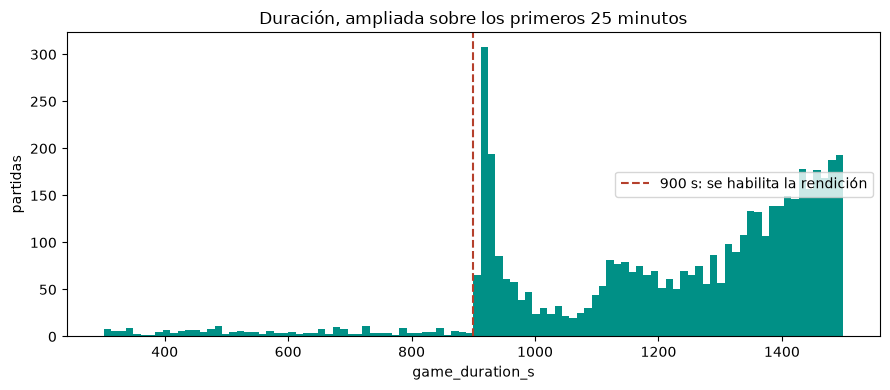

In [16]:
# El histograma, ampliado sobre los primeros veinticinco minutos
plt.figure(figsize=(9, 4))
plt.hist(dur[dur < 1500], bins=100, color=TEAL)
plt.axvline(900, color=LADRILLO, linestyle="--",
            label="900 s: se habilita la rendición")
plt.title("Duración, ampliada sobre los primeros 25 minutos")
plt.xlabel("game_duration_s")
plt.ylabel("partidas")
plt.legend(loc="center right")
plt.tight_layout()
plt.show()

La campana ancha de la vista general escondía esto. **Del minuto 14 al 15 hay
27 partidas; del 15 al 16 hay 714.** Un salto de veintiséis veces en sesenta
segundos, y después vuelve a caer a 198. Y de los diez valores de
duración más repetidos de las 19.145 partidas, **seis caen entre los 911 y
los 918 segundos** —911 y 912 son los dos primeros de la lista—: todos dentro
de los primeros veinte segundos posteriores a los 900.

La explicación es una regla del juego: **a los quince minutos exactos se habilita
la votación de rendición**, y no antes. Las partidas que ya estaban decididas se
terminan en cuanto el juego lo permite. No es un error de datos ni un artefacto
del pipeline: es el fenómeno, y el dataset lo captura con una nitidez que sirve
de control de calidad — si esa columna estuviera mal calculada, este escalón no
aparecería en el lugar exacto donde el reglamento dice que tiene que estar.

Tiene una consecuencia directa para la Unidad 3, y conviene anotarla ahora: el
objetivo **no es del todo continuo**. Tiene una acumulación de masa en 900
segundos que ningún modelo de regresión va a reproducir prediciendo un número
suave. Ese pico son 714 partidas, el 3,7 % del dataset.

### La distribución del objetivo, cuando el objetivo es continuo

La consigna verifica la distribución del objetivo con
`df["objetivo"].value_counts(normalize=True)` y pregunta si hay una clase que se
come todo. Esa fórmula **no aplica acá**: `game_duration_s` toma 2.180 valores
distintos, así que contar frecuencias devolvería una tabla de 2.180 filas con
casi un uno en cada una. El equivalente honesto es agrupar en bandas de
minutos, que es donde la pregunta *«¿hay una clase que se come todo?»*
recupera sentido.

In [17]:
# El sustituto de value_counts para un objetivo continuo: bandas de minutos
bandas = pd.cut(df["duracion_min"], bins=[0, 20, 25, 30, 35, 40, 100],
                labels=["<20", "20-25", "25-30", "30-35", "35-40", "40+"])
pd.DataFrame({"partidas": bandas.value_counts().sort_index(),
              "proporción": bandas.value_counts(normalize=True)
                                  .sort_index().round(3)})

,partidas,proporción
duracion_min,,
<20,1951,0.102
20-25,2882,0.151
25-30,5724,0.299
30-35,5014,0.262
35-40,2459,0.128
40+,1115,0.058


Ninguna banda se come el dataset: la más poblada, 25 a 30 minutos, tiene el
29,9 %. Las dos centrales juntas suman el 56,1 % y los extremos aportan el
10,2 % y el 5,8 %. **No hay desbalance que arruine el modelado**, que es
exactamente lo que la consigna quiere que se verifique ahora y no en octubre.

El reverso de la misma moneda: si el 56 % de las partidas dura entre 25 y 35
minutos, un modelo que prediga siempre 29 minutos ya va a parecer decente. El
umbral contra el que habrá que comparar en la Unidad 3 no es cero: es la media
constante.

### Las medidas de forma del resto de las numéricas

In [18]:
# Asimetría de todas las numéricas del esquema, de la más negativa a la más positiva
sk = df[ORIGINALES].select_dtypes("number").skew().sort_values()
pd.concat([sk.head(5), sk.tail(5)]).round(2)

t1_jng_rune_sub            -24.22
t2_bot_rune_sub            -24.14
t1_sup_rune_sub            -21.09
t2_mid_rune_sub            -17.86
t1_mid_rune_sub            -17.79
t2_bot_champ_mastery_pts     5.28
t2_sup_champ_mastery_pts     5.44
t1_bot_champ_mastery_pts     5.58
t1_sup_champ_mastery_pts     5.67
roles_inferidos             33.52
dtype: float64

Las dos puntas de esta lista son artefactos, y conviene entender cada una
antes de sacar conclusiones sobre colas largas.

Arriba, `roles_inferidos` con asimetría **33,52**: no es una variable sesgada,
es una bandera que vale 0 en casi todas las filas. Abajo, los `rune_sub` con
asimetría **−24**: tampoco son variables sesgadas, y de dónde sale ese número
se ve en la Sección 4. Para leer la asimetría de verdad hay que mirarla por
familia de columnas, que es la unidad en la que este dataset está construido.

In [19]:
# La asimetría mediana de cada familia de columnas
def familia(col):
    """El nombre de la familia: la columna sin el equipo y sin la posición."""
    k = col.removeprefix("t1_").removeprefix("t2_")
    for p in POS:
        k = k.removeprefix(p + "_")
    return k


num = df[ORIGINALES].select_dtypes("number")
por_familia = num.columns.to_series().map(familia)
num.skew().groupby(por_familia.values).median().sort_values().round(2)

rune_sub            -17.51
count_flash          -2.21
is_main              -0.75
mains_count          -0.45
total_base_hp        -0.36
avg_magic            -0.15
avg_attack           -0.15
avg_difficulty       -0.10
game_duration_s      -0.04
avg_attackrange      -0.00
num_fighters          0.03
total_base_armor      0.04
num_mages             0.06
player_winrate        0.10
count_ignite          0.10
avg_defense           0.12
num_assassins         0.25
num_tanks             0.35
sum2                  0.36
player_elo            0.42
sum1                  0.43
count_teleport        0.45
num_marksmen          0.52
num_supports          0.59
rune_primary          0.78
champ_id              1.71
champ_mastery_pts     4.67
roles_inferidos      33.52
dtype: float64

Leído por familia, el dataset es sorprendentemente parejo: casi todas las
familias están entre −0,5 y 0,6. Las dos que se despegan de verdad son
`champ_mastery_pts`, con **4,67**, y `champ_id`, con 1,71 — pero `champ_id` es
un código, así que su asimetría no significa nada: mide cómo Riot reparte los
números de identificación.

Queda una sola familia con cola larga real: los puntos de maestría.

In [20]:
# La maestría, mirada sobre los 191.450 jugadores
maestria = por_jugador("champ_mastery_pts")
maestria.describe(percentiles=[.25, .5, .75, .9, .99]).round(0)

count      191450.0
mean       380204.0
std        758224.0
min             0.0
25%         34543.0
50%        111880.0
75%        363174.0
90%       1011698.0
99%       3767042.0
max      13841137.0
Name: champ_mastery_pts, dtype: float64

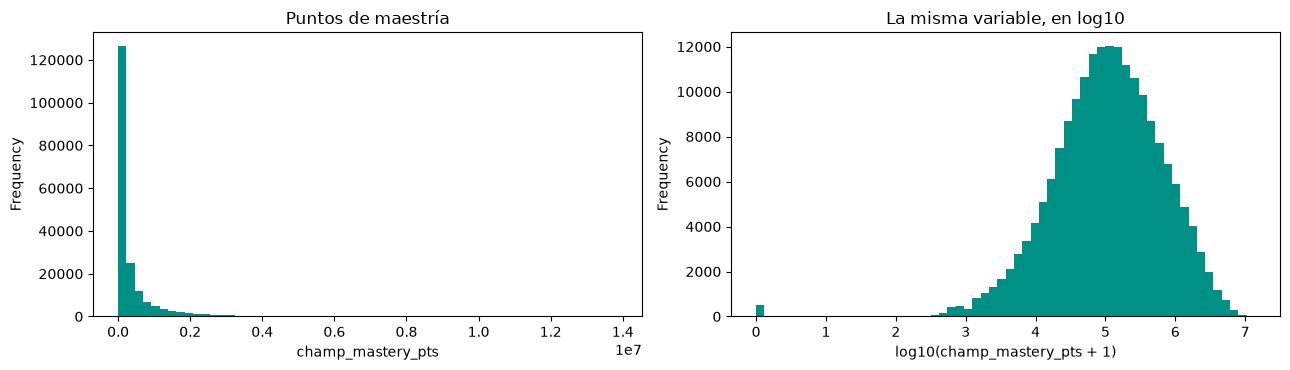

In [21]:
# La misma variable en escala lineal y en logarítmica
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
maestria.plot.hist(bins=60, color=TEAL, ax=axes[0])
axes[0].set_title("Puntos de maestría")
axes[0].set_xlabel("champ_mastery_pts")
np.log10(maestria + 1).plot.hist(bins=60, color=TEAL, ax=axes[1])
axes[1].set_title("La misma variable, en log10")
axes[1].set_xlabel("log10(champ_mastery_pts + 1)")
plt.tight_layout()
plt.show()

Mediana 111.880 puntos, percentil 90 en 1.011.698 y máximo **13.841.137**: el
10 % de los jugadores tiene más de un millón de puntos en el campeón que
eligió. Es el remedio estándar —escala logarítmica— y en log la distribución se
endereza en una campana ancha.

Un máximo de casi 14 millones de puntos en un solo campeón es lo bastante raro
como para desconfiar, así que lo verificamos contra el bronce en la Sección 4
antes de construir nada encima.

### La única categórica de texto: los campeones

In [22]:
# Cuántos campeones distintos aparecen, y cuáles son los extremos
campeones = por_jugador("champ_name")
pd.Series({"campeones distintos": campeones.nunique(),
           "apariciones del más jugado": campeones.value_counts().iloc[0],
           "apariciones del menos jugado": campeones.value_counts().iloc[-1]})

campeones distintos              173
apariciones del más jugado      3265
apariciones del menos jugado     230
dtype: int64

In [23]:
# La cabeza y la cola del reparto de campeones
pd.concat([campeones.value_counts().head(5),
           campeones.value_counts().tail(5)])

champ_name
Caitlyn    3265
Kaisa      3004
Sylas      3002
Lux        2845
Jhin       2827
RekSai      320
Skarner     308
Ivern       300
Renata      243
Nilah       230
Name: count, dtype: int64

173 campeones, de Caitlyn con 3.265 apariciones a Nilah con 230. La cola
importa tanto como la cabeza: son los campeones sobre los que cualquier
promedio que se calcule después va a estar sostenido por doscientos casos.

Con 173 niveles, `champ_name` no entra a un modelo sin transformarse: una
codificación *one-hot* de diez columnas de 173 niveles agrega 1.730 columnas a
un dataset de 19.145 filas. Es otra decisión para la tabla de candidatas.

# Sección 3 · Análisis bivariado

El objetivo de esta fase es estudiar relaciones entre pares de variables. Como
el proyecto tiene una columna objetivo declarada, la pregunta se ordena sola:
qué se mueve junto con la duración.

### Los agregados de equipo contra el objetivo

In [24]:
# Cada agregado del equipo 1 contra la duración, ordenado por fuerza
AGG = ["mains_count", "num_tanks", "num_mages", "num_assassins", "num_marksmen",
       "num_fighters", "num_supports", "avg_attack", "avg_defense", "avg_magic",
       "avg_difficulty", "avg_attackrange", "total_base_hp", "total_base_armor",
       "count_teleport", "count_ignite", "count_flash"]

corr_t1 = df[["game_duration_s"] + [f"t1_{a}" for a in AGG]].corr()
corr_t1["game_duration_s"].drop("game_duration_s") \
    .sort_values(key=abs, ascending=False).round(3)

t1_num_fighters       -0.046
t1_avg_magic           0.045
t1_num_mages           0.044
t1_total_base_armor   -0.040
t1_num_supports        0.035
t1_count_ignite        0.035
t1_avg_attackrange     0.035
t1_num_assassins      -0.030
t1_avg_attack         -0.026
t1_count_flash        -0.016
t1_avg_difficulty     -0.011
t1_total_base_hp       0.010
t1_num_marksmen        0.010
t1_count_teleport      0.010
t1_avg_defense        -0.006
t1_num_tanks           0.006
t1_mains_count        -0.002
Name: game_duration_s, dtype: float64

El agregado más asociado con la duración es `t1_num_fighters`, con **−0,046**.
Todos los demás están por debajo. Contra los cortes del semáforo —que se
definen en la Sección 7— eso es **rojo** con enorme margen: el corte más bajo
para una correlación es 0,2, y acá el máximo es la quinta parte de eso.

No es un detalle: es el resultado que ordena todo el resto del notebook.

### La matriz de correlación: las columnas se explican entre ellas, no al objetivo

In [25]:
# Con 17 agregados, 289 números sueltos no se leen: el color sí
corr_t1.style.background_gradient(cmap="RdBu", vmin=-1, vmax=1).format("{:.2f}")

,game_duration_s,t1_mains_count,t1_num_tanks,t1_num_mages,t1_num_assassins,t1_num_marksmen,t1_num_fighters,t1_num_supports,t1_avg_attack,t1_avg_defense,t1_avg_magic,t1_avg_difficulty,t1_avg_attackrange,t1_total_base_hp,t1_total_base_armor,t1_count_teleport,t1_count_ignite,t1_count_flash
game_duration_s,1.00,-0.00,0.01,0.04,-0.03,0.01,-0.05,0.03,-0.03,-0.01,0.05,-0.01,0.03,0.01,-0.04,0.01,0.03,-0.02
t1_mains_count,-0.00,1.00,-0.05,0.01,0.03,-0.02,-0.01,0.03,0.01,-0.01,0.01,0.08,0.02,-0.00,0.02,-0.04,-0.02,-0.01
t1_num_tanks,0.01,-0.05,1.00,-0.29,-0.41,-0.15,0.07,-0.00,-0.03,0.56,-0.11,-0.21,-0.35,0.30,0.38,0.08,0.02,-0.05
t1_num_mages,0.04,0.01,-0.29,1.00,-0.25,-0.04,-0.39,0.11,-0.50,-0.17,0.54,0.01,0.46,-0.20,-0.47,0.14,-0.21,0.03
t1_num_assassins,-0.03,0.03,-0.41,-0.25,1.00,-0.12,0.12,-0.27,0.35,-0.17,-0.24,0.17,-0.35,0.14,0.19,-0.20,0.26,0.04
t1_num_marksmen,0.01,-0.02,-0.15,-0.04,-0.12,1.00,-0.30,-0.12,0.27,-0.18,-0.15,-0.04,0.35,-0.08,-0.21,-0.11,-0.09,0.05
t1_num_fighters,-0.05,-0.01,0.07,-0.39,0.12,-0.30,1.00,-0.25,0.37,0.12,-0.26,-0.03,-0.39,0.11,0.32,-0.10,0.11,-0.01
t1_num_supports,0.03,0.03,-0.00,0.11,-0.27,-0.12,-0.25,1.00,-0.32,-0.06,0.16,-0.06,0.29,-0.19,-0.14,0.10,-0.15,0.02
t1_avg_attack,-0.03,0.01,-0.03,-0.50,0.35,0.27,0.37,-0.32,1.00,-0.02,-0.49,0.04,-0.31,0.25,0.36,-0.22,0.16,-0.04
t1_avg_defense,-0.01,-0.01,0.56,-0.17,-0.17,-0.18,0.12,-0.06,-0.02,1.00,0.06,-0.07,-0.37,0.40,0.40,0.06,0.05,0.02


In [26]:
# Los pares de agregados que miden casi lo mismo
cc = corr_t1.drop(index="game_duration_s", columns="game_duration_s")
pares = (cc.where(np.triu(np.ones(cc.shape), 1).astype(bool))
           .stack().sort_values(key=abs, ascending=False))
pares[abs(pares) > 0.5].round(3)

t1_avg_attackrange  t1_total_base_armor   -0.654
t1_num_tanks        t1_avg_defense         0.558
t1_num_mages        t1_avg_magic           0.544
t1_count_teleport   t1_count_ignite       -0.543
t1_total_base_hp    t1_total_base_armor    0.515
t1_num_mages        t1_avg_attack         -0.502
dtype: float64

La fila y la columna del objetivo son una banda pálida: nada se pinta fuerte
contra `game_duration_s`. Pero el resto de la matriz sí tiene bloques de color,
y ahí aparece la redundancia.

`avg_attackrange` y `total_base_armor` correlacionan **−0,654**: los campeones
de rango largo son de armadura baja, así que las dos columnas cuentan la misma
historia con el signo dado vuelta. `num_tanks` con `avg_defense` **0,558** y
`num_mages` con `avg_magic` **0,544** son casi definiciones: contar tanques y
promediar defensa miden lo mismo dos veces.

Y el par más interesante es `count_teleport` con `count_ignite`, **−0,543**:
son dos hechizos que compiten por el mismo espacio, así que llevar uno implica
no llevar el otro. Ninguno de los tres pares aporta al objetivo, pero los tres
importan para la tabla de candidatas: **darle a un modelo dos columnas que
miden lo mismo reparte el peso entre las dos y hace que ninguna parezca
importante.**

### Una numérica contra una categórica: el servidor

In [27]:
# La duración por servidor, con el tamaño de cada grupo
df.groupby("plataforma")["game_duration_s"] \
  .agg(["size", "mean", "median", "std"]).round(1)

,size,mean,median,std
plataforma,,,,
BR1,3333,1687.0,1691.0,403.6
EUW1,2950,1743.4,1736.5,378.5
KR,3430,1688.6,1698.0,462.0
LA1,3355,1722.1,1718.0,383.2
LA2,3066,1837.0,1842.0,422.4
NA1,3011,1825.7,1834.0,461.7


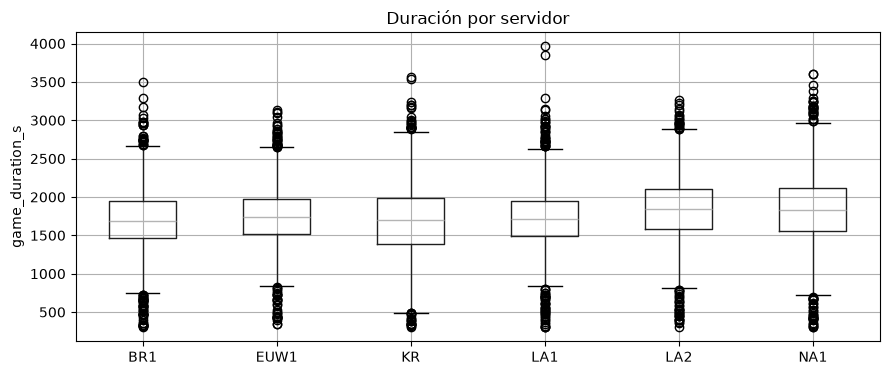

In [28]:
# Seis grupos grandes: el boxplot muestra cuánto se solapan
df.boxplot(column="game_duration_s", by="plataforma", figsize=(9, 4))
plt.title("Duración por servidor")
plt.suptitle("")
plt.xlabel("")
plt.ylabel("game_duration_s")
plt.tight_layout()
plt.show()

Las medias van de 1.687 segundos en BR1 a 1.837 en LA2: **dos minutos y medio
de diferencia entre el servidor más rápido y el más lento**, sobre desvíos
estándar de unos 400 segundos. Las seis cajas se pisan casi por completo.

Es el primer caso de comparación entre muchos grupos, y la medida que
corresponde es η². Se calcula en la Sección 7 junto con el resto del método,
pero adelantamos el número porque hace falta acá: **η² = 0,020**, o sea que
saber en qué servidor se jugó explica el 2 % de la variación de la duración.

In [29]:
# ¿Y si en vez del servidor usamos el campeón, que tiene 158 niveles?
def eta2(numerica, categoria):
    """Proporción de la varianza de la numérica que explica la categoría."""
    g = numerica.groupby(categoria)
    m = numerica.mean()
    return (g.count() * (g.mean() - m) ** 2).sum() / ((numerica - m) ** 2).sum()


pd.Series({c: eta2(dur, df[c]) for c in
           ["plataforma", "t1_top_champ_name", "t1_jng_champ_name",
            "t1_mid_champ_name", "roles_inferidos"]}).round(4)

plataforma           0.0201
t1_top_champ_name    0.0136
t1_jng_champ_name    0.0116
t1_mid_champ_name    0.0162
roles_inferidos      0.0008
dtype: float64

Ni siquiera el campeón del carril central, con 158 valores distintos, pasa de
**0,016**. Y eso es una cota superior generosa: η² sube con la cantidad de
grupos, así que 158 categorías tienen todas las chances de capturar variación
por puro azar y aun así no llegan al 2 %.

La lectura combinada de las tres celdas anteriores es la misma: **ninguna
columna sola, numérica o categórica, distingue una partida larga de una corta.**

# Sección 4 · Análisis de calidad de datos

El objetivo de esta fase es decidir qué hay que limpiar antes de modelar. En
este dataset la respuesta corta es «nada», y la parte interesante es *por qué*:
casi todas las decisiones de limpieza se tomaron aguas arriba, en el pipeline,
y hay que poder defender cada una.

### La clave: primero hay que elegir qué cuenta como la misma fila

In [30]:
# La misma pregunta con tres claves distintas
pd.Series({"por match_id": df["match_id"].duplicated().sum(),
           "por fila completa": df.duplicated(subset=ORIGINALES).sum(),
           "por los 10 campeones": df.duplicated(
               subset=[f"{e}_{p}_champ_id" for e in EQUIPOS for p in POS]).sum()})

por match_id            0
por fila completa       0
por los 10 campeones    0
dtype: int64

Las tres dan cero, y la tercera es la que enseña algo. Que la composición de
los diez campeones no se repita **ni una sola vez** en 19.145 partidas no es un
chequeo de integridad: es una medida de cuán grande es el espacio de
composiciones. Con 173 campeones para repartir en diez lugares, dos partidas
idénticas son un evento tan raro que no aparece.

Eso tiene una consecuencia directa para la Unidad 3, y conviene anotarla ahora:
si cada fila trae una composición única, un modelo no puede aprender «esta
combinación de campeones dura tanto». Va a tener que aprender de las
características agregadas de la composición, que es exactamente lo que el
bloque C intenta resumir.

Que la clave dé cero no es casualidad: la tarea `consolidate` del DAG hace
`drop_duplicates("match_id")` antes de escribir, y la tarea `validate` falla la
corrida entera si la clave repite. El cero es el resultado de una decisión, no
una propiedad de la fuente.

### Columnas sin información, y las que casi no tienen

In [31]:
# Columnas constantes
df[ORIGINALES].columns[df[ORIGINALES].nunique() <= 1].tolist()

[]

In [32]:
# Ninguna es constante, pero algunas están cerca: cuánto pesa su valor más común
modal = pd.Series({c: df[c].value_counts(normalize=True).iloc[0]
                   for c in ORIGINALES})
pd.DataFrame({"valor_modal": modal.round(4),
              "valores_distintos": df[ORIGINALES].nunique()}) \
    .sort_values("valor_modal", ascending=False).head(6)

,valor_modal,valores_distintos
roles_inferidos,0.9991,2
t1_count_flash,0.8382,4
t2_count_flash,0.8356,4
t2_bot_rune_primary,0.7593,5
t1_bot_rune_primary,0.7573,5
t2_bot_is_main,0.7054,2


No hay ninguna columna constante, y eso también es el resultado de una
decisión previa: `count_smite` sí era constante —el juego obliga al jungla a
llevar Smite, así que valía 1 en toda partida real— y se quitó del esquema
antes de la Entrega 1. El chequeo que la encontraría hoy devuelve una lista
vacía porque ya se actuó.

Las casi constantes son otra historia. **`roles_inferidos` vale 0 en el
99,91 % de las filas**: sólo 17 partidas de 19.145 tuvieron algún jugador sin
`teamPosition`. Y los dos `count_flash` tienen su valor modal en el 84 %.

In [33]:
# Las 17 filas que la bandera de calidad marca
df["roles_inferidos"].value_counts()

roles_inferidos
0    19128
1       17
Name: count, dtype: int64

`roles_inferidos` cumplió su función —dejar rastro de las filas dudosas para
poder filtrarlas— y el número dice que el problema que temíamos casi no
existe. Como columna para un modelo no sirve: una bandera que vale lo mismo en
el 99,91 % de las filas no puede distinguir nada. **Sale como feature y queda
como herramienta de filtrado**, y eso va a la tabla de candidatas.

### Valores faltantes: cero, y ése es justamente el tema

In [34]:
# Nulos por columna, las peores primero
df[ORIGINALES].isna().mean().sort_values(ascending=False).head(3)

match_id           0.0
game_duration_s    0.0
roles_inferidos    0.0
dtype: float64

No hay un solo nulo en las 137 columnas. Eso suena bien y no lo es del todo:
la consigna pide distinguir los faltantes de verdad de los nulos
estructurales, y acá hay una **tercera categoría** que hay que declarar porque
es la que aplica.

Los faltantes existieron y se convirtieron en valores por defecto aguas
arriba, en el pipeline. Un jugador sin entrada de `RANKED_SOLO_5x5` —porque
está sin clasificar o sólo juega flexible— recibe `player_elo = 1500` y
`player_winrate = 0.50`. La decisión fue deliberada, con este argumento: un
jugador sin ranked **es** un jugador de habilidad desconocida, y 1500 / 0,50
codifica «promedio, sin información».

El precio de esa decisión es que el faltante ya no se puede contar con
`isna()`. Se cuenta buscando el valor exacto que se usó para imputar.

In [35]:
# La masa de valores imputados, en celdas de jugador (10 x 19.145 = 191.450)
celdas = 10 * len(df)
rp_cols = [f"{e}_{p}_rune_primary" for e in EQUIPOS for p in POS]
rs_cols = [f"{e}_{p}_rune_sub" for e in EQUIPOS for p in POS]
im_cols = [f"{e}_{p}_is_main" for e in EQUIPOS for p in POS]

pd.Series({
    "player_elo == 1500": (df[elo_cols] == 1500).sum().sum() / celdas,
    "player_winrate == 0.50": (df[wr_cols] == 0.50).sum().sum() / celdas,
    "las dos cosas a la vez": ((df[elo_cols].to_numpy() == 1500)
                               & (df[wr_cols].to_numpy() == 0.50)).sum() / celdas,
    "champ_mastery_pts == 0": (df[mas_cols] == 0).sum().sum() / celdas,
    "rune_primary == 0": (df[rp_cols] == 0).sum().sum() / celdas,
    "rune_sub == 0": (df[rs_cols] == 0).sum().sum() / celdas,
}).round(4)

player_elo == 1500        0.0055
player_winrate == 0.50    0.0357
las dos cosas a la vez    0.0049
champ_mastery_pts == 0    0.0027
rune_primary == 0         0.0000
rune_sub == 0             0.0001
dtype: float64

La imputación afecta al **0,55 %** de las celdas de jugador si se la busca por
el elo. Es poco, y es la respuesta a *«por qué hay nulos donde hay nulos»*: no
hay nulos porque el 0,55 % de los casos se resolvió con un valor promedio, a
propósito y con el criterio escrito.

Pero la tabla trae una trampa que conviene ver ahora. `player_winrate == 0.50`
aparece en el **3,57 %** de las celdas, siete veces más que el elo imputado: la
mayoría de esos casos son jugadores reales con un historial parejo de verdad
—uno y uno, cinco y cinco—. Y al revés, el elo 1500 tampoco identifica sólo
imputaciones: un jugador SILVER III con 50 puntos de liga da exactamente 1500,
porque la fórmula del proxy de elo es `1400 + 75 + 25`.

**Ninguno de los dos valores, por separado, identifica una imputación.** Los dos
juntos se acercan, y cuánto se acercan es medible.

In [36]:
# Cuánto depura el proxy combinado respecto de mirar sólo el elo
solo_elo = int((df[elo_cols].to_numpy() == 1500).sum())
ambos = int(((df[elo_cols].to_numpy() == 1500)
             & (df[wr_cols].to_numpy() == 0.50)).sum())
pd.Series({"celdas con elo == 1500": solo_elo,
           "celdas con elo == 1500 y winrate == 0.50": ambos,
           "celdas que el proxy combinado descarta": solo_elo - ambos})

celdas con elo == 1500                      1055
celdas con elo == 1500 y winrate == 0.50     944
celdas que el proxy combinado descarta       111
dtype: int64

In [37]:
# Cuántos jugadores imputados tiene cada partida
df["jugadores_imputados"].value_counts().sort_index()

jugadores_imputados
0     18530
1       512
2        62
3         6
4         1
5         3
7         5
9        24
10        2
Name: count, dtype: int64

El proxy combinado descarta **111** de las 1.055 celdas que el elo solo habría
marcado: son los SILVER III con 50 LP, exactamente el falso positivo que
anticipábamos. Quedan 944 celdas de jugador imputadas, repartidas en 615
partidas.

El reparto por partida trae algo que no esperábamos y que hay que mirar de
frente. La mayoría de las partidas afectadas tiene **un** jugador imputado, lo
cual es razonable. Pero hay **24 partidas con 9 jugadores imputados y 2 con los
10**, y eso no es razonable: nueve jugadores sin clasificar en la misma partida
clasificatoria es prácticamente imposible. Es mucho más probable que sea el
pipeline —una tanda de consultas a League-V4 que falló para toda la partida y
cayó al valor por defecto— que un hecho del juego. No lo podemos confirmar acá,
porque para eso hay que mirar el bronce de esas 26 partidas y el bronce de la
corrida grande está en otra máquina. **Queda anotado como pendiente**, y es una
de las respuestas a qué quedó inconcluso.

Si esas 615 partidas además *duran* distinto que el resto es otra pregunta, y se
contesta con una medida del semáforo. Se cierra en la Sección 9, junto con la
decisión sobre la columna que la documentación tenía abierta.

### Dos ceros, dos significados, en el mismo archivo

In [38]:
# Un cero puede ser un valor real o un faltante disfrazado: hay que mirar quién es
pd.DataFrame({
    "ceros": [(df[mas_cols] == 0).sum().sum(), (df[rs_cols] == 0).sum().sum()],
    "qué significa": ["nunca jugó ese campeón: es un cero real",
                      "el payload no traía perks.styles[1]: es un faltante"]},
    index=["champ_mastery_pts", "rune_sub"])

,ceros,qué significa
champ_mastery_pts,512,nunca jugó ese campeón: es un cero real
rune_sub,27,el payload no traía perks.styles[1]: es un fal...


In [39]:
# Y esos 27 ceros son los que rompen la asimetría de una columna entera
con_ceros = df["t1_jng_rune_sub"]
sin_ceros = con_ceros[con_ceros != 0]
pd.Series({"asimetría con los ceros": con_ceros.skew(),
           "asimetría sin los ceros": sin_ceros.skew(),
           "celdas quitadas": (con_ceros == 0).sum()}).round(2)

asimetría con los ceros   -24.22
asimetría sin los ceros    -0.40
celdas quitadas             5.00
dtype: float64

Acá está el origen del −24 de la Sección 2. **Cinco celdas** de 19.145 mueven
la asimetría de `t1_jng_rune_sub` de −24,22 a −0,40. La columna no está
sesgada: tiene cinco ceros entre valores que van de 8.000 a 8.400, y esa
distancia es enorme en unidades de desvío estándar aunque sean sólo cinco
casos.

La moraleja es la que pide la teórica: **un criterio automático sobre la
asimetría habría marcado esta columna para transformar, y transformarla no
arregla nada.** Lo que corresponde es tratar los cinco ceros como el faltante
que son. El cero de `champ_mastery_pts`, en cambio, es un cero de verdad —el
jugador nunca tocó ese campeón— y hay que dejarlo.

### Valores extremos: legítimos, no errores de carga

In [40]:
# Los extremos del objetivo, y cuántos son
pd.Series({"partidas de menos de 10 min": (dur < 600).sum(),
           "partidas de más de 45 min": (dur > 2700).sum(),
           "partidas de más de 50 min": (dur > 3000).sum(),
           "la más larga (s)": dur.max(),
           "la más corta (s)": dur.min()})

partidas de menos de 10 min     137
partidas de más de 45 min       289
partidas de más de 50 min        61
la más larga (s)               3963
la más corta (s)                301
dtype: int64

289 partidas pasan los 45 minutos y 137 quedan por debajo de 10. Un boxplot
las marcaría como atípicas y hay que resistir la tentación: una partida de
66 minutos es una partida real que se fue a *late game*, y una de 5 minutos es
una rendición temprana. **No son errores: son el fenómeno.** Sacarlas
recortaría justamente las filas que un modelo de duración tiene que poder
explicar.

El único recorte legítimo ya está hecho aguas arriba, y es el de los remakes
por debajo de 300 segundos.

### El chequeo que no estaba en el checklist: contra el bronce

Un máximo de 13.841.137 puntos de maestría en un solo campeón es raro. Como el
pipeline guarda el bronce —la respuesta de la API tal como llegó— se puede
verificar si el número es de Riot o es nuestro. Corrimos esa comparación sobre
las 20 partidas del bronce que hay en esta máquina, jugador por jugador y
campeón por campeón:

| Qué | Resultado |
|---|---|
| Celdas comparadas contra el `championPoints` del bronce | 200 |
| Coincidencias exactas | **200** |
| Discrepancias | 0 |

El valor de la plata es exactamente el `championPoints` que devuelve
Champion-Mastery-V4 para ese jugador y ese campeón: no está sumando todos los
campeones ni acumulando nada. Los 13,8 millones son un *one-trick* real, y la
columna se puede usar con confianza.

Es la respuesta a la pregunta *«si mañana descubrís que venías interpretando
mal una columna, ¿podés arreglarlo sin volver a la fuente?»*: sí, y esto es
una demostración de para qué sirve tener el bronce.

### Inconsistencias de codificación

In [41]:
# ¿El código del campeón y su nombre son la misma información dos veces?
ids = por_jugador("champ_id")
nombres = por_jugador("champ_name")
pares_cn = pd.DataFrame({"id": ids, "nombre": nombres})
pd.Series({"campeones por id": pares_cn["id"].nunique(),
           "campeones por nombre": pares_cn["nombre"].nunique(),
           "nombres con más de un id":
               (pares_cn.groupby("nombre")["id"].nunique() > 1).sum(),
           "filas con nombre 'Unknown'": (nombres == "Unknown").sum()})

campeones por id              173
campeones por nombre          173
nombres con más de un id        0
filas con nombre 'Unknown'      0
dtype: int64

173 y 173, el mapeo es uno a uno y no hay ni un `Unknown`. Las dos cosas
importan.

El mapeo uno a uno significa que **`champ_id` y `champ_name` son la misma
columna escrita dos veces**: una de las dos sale, y la que se queda es la que
convenga a la codificación que se elija en la Unidad 3.

Y que no haya ningún `Unknown` cierra un riesgo que el pipeline anticipaba: el
esquema pone `"Unknown"` cuando un campeón es más nuevo que el snapshot de Data
Dragon. Que el conteo dé cero dice que el snapshot 16.17.1 cubre los 173
campeones que aparecen, y por lo tanto que **ninguna fila aporta ceros falsos a
los agregados de composición** del equipo. Era la falla silenciosa más probable
del bloque C, y no ocurrió.

# Sección 5 · Un dataset sin eje temporal

Antes de buscar tendencias, estacionalidad o ciclos hay que preguntarse algo
más básico: **¿este dataset tiene dimensión temporal?** No todos la tienen, y
reconocerlo también es parte del análisis exploratorio.

In [42]:
# ¿Hay alguna columna de fecha, o algo que se pueda convertir en fecha?
es_fecha = pd.api.types.is_datetime64_any_dtype
es_texto = pd.api.types.is_string_dtype
pd.Series({"columnas de tipo fecha": sum(es_fecha(df[c]) for c in ORIGINALES),
           "columnas con 'date' o 'time' en el nombre":
               sum(("date" in c or "time" in c) for c in ORIGINALES),
           "columnas de texto (candidatas a parsear)":
               sum(es_texto(df[c]) for c in ORIGINALES)})

columnas de tipo fecha                        0
columnas con 'date' o 'time' en el nombre     0
columnas de texto (candidatas a parsear)     11
dtype: int64

No hay ninguna. Las 137 columnas del esquema son códigos, conteos y
promedios: **el dataset no guarda cuándo se jugó cada partida.** No es un
descuido del pipeline sino una consecuencia del recorte: el esquema se limitó a
condiciones iniciales de la partida, y la fecha de juego no es una condición
inicial que sirva para predecir la duración.

Tampoco hay variación de parche que pudiera hacer de eje: el filtro de admisión
exige que `gameVersion` empiece con `16.`, así que las 19.145 partidas caen
dentro de una misma temporada, y los agregados del bloque C se calcularon todos
contra un único *snapshot* de Data Dragon, el 16.17.1. Si mañana Riot cambia el
balance de un campeón, este dataset no lo va a saber.

**Conclusión de la fase: no hay tendencia, estacionalidad ni ciclos que medir**,
y las técnicas de la fase 5 no aplican. Lo que sí hay que declarar es la
consecuencia: el dataset es una **ventana de recolección**, una foto de unos
días de septiembre de 2026 en seis servidores, y cualquier conclusión que salga
de acá vale para esa ventana.

# Sección 6 · De la exploración a las hipótesis

El análisis exploratorio no termina en un resumen: termina en preguntas mejores
que las del principio. Lo que dejaron las cinco fases anteriores:

1. **El objetivo no necesita transformarse.** Asimetría −0,039 y curtosis 0,579:
   una campana ancha centrada en 1.748 segundos. Es lo contrario de lo que suele
   pasar con una variable de tiempo, y hay que aprovecharlo.
2. **Está truncado a izquierda en 300 segundos**, por decisión nuestra, y ningún
   modelo va a ver partidas más cortas que eso.
3. **Y no es del todo continuo: tiene un escalón en 900 segundos.** Del minuto
   14 al 15 hay 27 partidas y del 15 al 16 hay 714, porque a los quince minutos
   se habilita la rendición. Son el 3,7 % del dataset acumulado en un punto.
4. **No hay desbalance del objetivo**: la banda más poblada, 25 a 30 minutos,
   tiene el 29,9 %. El rival a batir en la Unidad 3 es la media constante.
5. **No hay nulos, y ésa es una decisión, no una propiedad.** El 0,55 % de las
   celdas de jugador tiene el elo imputado en 1500, y buscar esa imputación es
   difícil: `elo == 1500` también le pasa a un SILVER III con 50 LP.
6. **Ninguna columna sola se mueve con el objetivo.** El máximo del dataset es
   `elo_partida` con −0,161, y el mejor agregado crudo es `t1_num_fighters` con
   −0,046. Ni el campeón del carril central, con 158 niveles, pasa de η² 0,016.
7. **Las columnas sí se explican entre ellas.** `avg_attackrange` con
   `total_base_armor` −0,654, `count_teleport` con `count_ignite` −0,543,
   `num_tanks` con `avg_defense` 0,558: hay redundancia para recortar.
8. **Cinco celdas mueven una asimetría de −24 a −0,40.** Los ceros de
   `rune_sub` son faltantes disfrazados, y un criterio automático sobre el skew
   habría decidido mal.

Los puntos 6 y 7 juntos son los que ordenan la Sección 8, y conviene decir por
qué. **Contra el objetivo no hay nada** —eso ya está medido tres veces— pero
**entre las columnas sí hay estructura**, y la consigna pide las dos clases de
hipótesis: las que responden algo sobre el dominio y las que deciden sobre una
columna del modelo. Las segundas no necesitan pasar por la duración para ser
útiles: una columna que duplica a otra sale del modelo aunque las dos sean
igual de inútiles para predecir.

### Las preguntas que quedaron abiertas

- ¿El nivel de los jugadores acorta la partida, como dice el sentido común del
  juego? El −0,161 dice que no, pero es la columna más fuerte que tenemos y
  merece la ficha entera. → **H1**
- ¿Y si lo que importa no es el nivel sino la composición? Los tanques son el
  caso de manual: alargan las peleas y dificultan cerrar. → **H2**
- El −0,654 entre el alcance de ataque y la armadura base apareció sin que lo
  buscáramos. ¿Es una regularidad de diseño del juego, y entonces una de las
  dos columnas sobra? → **H3**
- `player_elo` y `player_winrate` se leen de la misma respuesta de la API y
  pretenden medir lo mismo. ¿Lo miden? → **H4**
- De las columnas que casi no varían, ¿alguna se puede sacar con un número que
  lo respalde, como se hizo con `count_smite`? → **H5**
- El bloque C cuenta la composición dos veces: con los tags de rol y con las
  estadísticas base promediadas. ¿Cuánto se pisan? → **H6**
- `is_main` binariza la maestría en un umbral que elegimos nosotros. ¿La
  binarización conserva la información de la columna continua? → **H7**
- Los rótulos `t1` y `t2` los asigna Riot arbitrariamente. ¿Entonces las 34
  columnas de equipo no son 17 columnas repetidas? → **H8**

Y una dirección que **no** se convirtió en ficha, pero quedó con su número
medido, porque es lo único del dataset que mostró estructura clara contra el
objetivo: comparando la proporción de cada campeón en el cuartil de partidas más
largas contra su proporción global, Brand aparece 1,35 veces más de lo que le
tocaría, Teemo 1,35, Morgana 1,28 y Lux 1,28; en el otro extremo Kalista aparece
0,61 veces y Bel'Veth 0,62. La lista de arriba son magos de zona y campeones de
asedio, y la de abajo, campeones de bola de nieve temprana. Es la plantilla de
**composición**, no está entre las ocho fichas, y quedaría como la primera
candidata a novena.

# Sección 7 · El método: cómo se resuelve una hipótesis

Una hipótesis no se contesta con un gráfico: se contesta con **un número**, y el
gráfico explica ese número. La razón es que un gráfico no se compara contra
nada. Un número, en cambio, se compara contra un corte fijado de antemano, y
por eso puede decir *terminá acá*.

**La regla del orden.** La afirmación y lo que se espera ver se escriben *antes*
de correr la medida. Podemos usar todo lo que ya sabíamos, pero no el resultado
que estamos por calcular: si al releer una hipótesis se nota que se escribió
después de mirar el gráfico, no se está poniendo a prueba nada.

Hay dos clases de «lo que ya sabíamos» y conviene distinguirlas, porque no se
defienden igual. Seis de las ocho afirmaciones salen de lo que el grupo sabe del
juego o del pipeline, y se fijaron antes de calcular un solo coeficiente. Las
otras dos —**H3 y H6**— salen de algo que apareció en la fase 3 sin que lo
buscáramos: la matriz de correlación mostró bloques de color entre columnas.
Eso es exactamente lo que la fase 6 dice que tiene que pasar —«el EDA ayuda a
formular nuevas preguntas»— y las dos fichas lo declaran en su primera casilla.
Lo que ninguna de las ocho hace es elegir la medida después de ver cuál conviene:
la plantilla la fija la forma de la afirmación, y en H6, donde η² y Pearson dan
zonas distintas, los dos números están a la vista.

### Las tres plantillas, y la forma trae la medida

| Forma | Se escribe | Medida |
|---|---|---|
| Comparación | «X difiere entre A y B» | separación estandarizada, o η² con varios grupos |
| Asociación | «X se mueve junto con Y» | Pearson y Spearman |
| Composición | «C está sobrerrepresentada en G» | proporción del grupo contra la global |

Si se sabe en qué plantilla cae la hipótesis, ya se sabe qué número hay que
calcular, y no se elige después de ver cuál conviene.

In [43]:
# Las tres medidas de la cátedra (eta2 ya quedó definida en la Sección 3)
def separacion(x, y):
    """Distancia entre dos muestras, en desviaciones estándar."""
    x, y = x.dropna(), y.dropna()
    return abs(x.mean() - y.mean()) / np.sqrt((x.std() ** 2 + y.std() ** 2) / 2)


def asociacion(x, y):
    """Pearson, Spearman y la brecha entre ambos."""
    p, s = x.corr(y), x.corr(y, method="spearman")
    return pd.Series({"pearson": p, "spearman": s, "brecha": s - p}).round(3)


# Un control de que las tres hacen lo que dicen, sobre casos de respuesta conocida
pd.Series({"separación de una variable contra sí misma": separacion(dur, dur),
           "asociación de una variable contra sí misma": asociacion(dur, dur)["pearson"],
           "eta2 de una variable contra sí misma": eta2(dur, dur)}).round(3)

separación de una variable contra sí misma    0.0
asociación de una variable contra sí misma    1.0
eta2 de una variable contra sí misma          1.0
dtype: float64

### El semáforo

Falta la parte que convierte un número en una decisión, y hay un motivo por el
que hace falta: con 19.145 filas **casi cualquier diferencia da
estadísticamente significativa**. La prueba de hipótesis clásica responde
«¿esta diferencia es real o es ruido?», y con esta cantidad de datos la
respuesta es casi siempre «es real». Pero real no es lo mismo que importante.
El semáforo no pregunta si el efecto existe: pregunta **si es lo bastante
grande como para cambiar una decisión**.

Los cortes se aplican sobre el **valor absoluto**: el signo dice la dirección y
se lee aparte.

In [44]:
# Los cortes de la cátedra, y la función que devuelve la zona
CORTES = {"separacion": (0.2, 0.8), "eta2": (0.05, 0.25),
          "correlacion": (0.2, 0.6), "brecha": (0.05, 0.15)}


def semaforo(valor, medida):
    """Devuelve la zona en la que cae el valor, según la medida usada."""
    bajo, alto = CORTES[medida]
    v = abs(valor)
    return "rojo" if v < bajo else "verde" if v > alto else "amarillo"


pd.DataFrame({m: {"rojo": f"< {b}", "amarillo": f"{b} a {a}", "verde": f"> {a}"}
              for m, (b, a) in CORTES.items()})

,separacion,eta2,correlacion,brecha
rojo,< 0.2,< 0.05,< 0.2,< 0.05
amarillo,0.2 a 0.8,0.05 a 0.25,0.2 a 0.6,0.05 a 0.15
verde,> 0.8,> 0.25,> 0.6,> 0.15


### Qué hacer con cada color

**Verde** y **rojo** terminan la hipótesis: el efecto es claro, o no está.
**Amarillo** es el único que habilita seguir, y seguir quiere decir hacer un
**movimiento**: cambiar algo del análisis y volver a medir. Hay tres, y el
gráfico decide cuál:

| Movimiento | Cuándo se usa |
|---|---|
| Partir la población | el gráfico muestra grupos que se comportan distinto |
| Controlar una tercera variable | la relación observada contradice algo que sabemos cierto |
| Cambiar la escala | la brecha entre Spearman y Pearson es grande |

Hay un tope de **dos movimientos por hipótesis**: si después del segundo el
número sigue amarillo, la conclusión es *inconclusa*. Sin tope, partiendo el
dataset lo suficiente cualquier hipótesis termina confirmada.

# Sección 8 · Las ocho fichas

Las tres primeras nacen de la pregunta **qué queremos responder** y terminan en
una conclusión sobre el juego. Las cinco últimas nacen de **qué queremos
predecir** y terminan en una decisión sobre una columna: entra, sale o se
transforma.

Cuatro de las ocho terminan en verde y cuatro en rojo, y la diferencia entre los
dos grupos no es la calidad de la hipótesis sino **contra qué se mide**. Las
cuatro rojas apuntan al objetivo; las cuatro verdes miden columnas entre sí. Eso
no es un accidente de las preguntas que elegimos: es el resultado de fondo del
dataset, y está medido en la Sección 9.

## H1 · A más elo, las partidas son más cortas

**Afirmación.** Cuanto mejores son los diez jugadores de una partida, más corta
es: los jugadores de nivel alto convierten una ventaja en objetivos más rápido,
cierran antes y no estiran partidas que ya están decididas.

**Qué espero ver.** Una nube que baja hacia la derecha. No espero una
correlación fuerte —la duración depende de muchas cosas— pero sí que sea la más
fuerte del dataset, porque el elo es lo único que mide directamente cuán bien
se juega.

**Por qué esta medida.** Es una asociación entre dos numéricas, así que van
Pearson y Spearman. La brecha entre los dos hace de control: si la relación
existiera pero fuera curva, Pearson la subestimaría y Spearman no.

In [45]:
# El elo medio de los 10 jugadores contra la duración
h1 = asociacion(df["elo_partida"], dur)
h1

pearson    -0.161
spearman   -0.155
brecha      0.006
dtype: float64

In [46]:
# La zona de cada uno de los dos números
pd.Series({"correlación": semaforo(h1["pearson"], "correlacion"),
           "brecha": semaforo(h1["brecha"], "brecha")})

correlación    rojo
brecha         rojo
dtype: str

**Resultado.** Pearson **−0,161** y Spearman **−0,155**: los dos en **rojo**.
La brecha es 0,006, también rojo, así que no hay curvatura escondida. El signo
es el que esperábamos y la magnitud no alcanza: **la hipótesis se refuta y acá
termina.** El gráfico no hace falta para decidir, pero conviene mirarlo una vez
para asociar el número con lo que se ve.

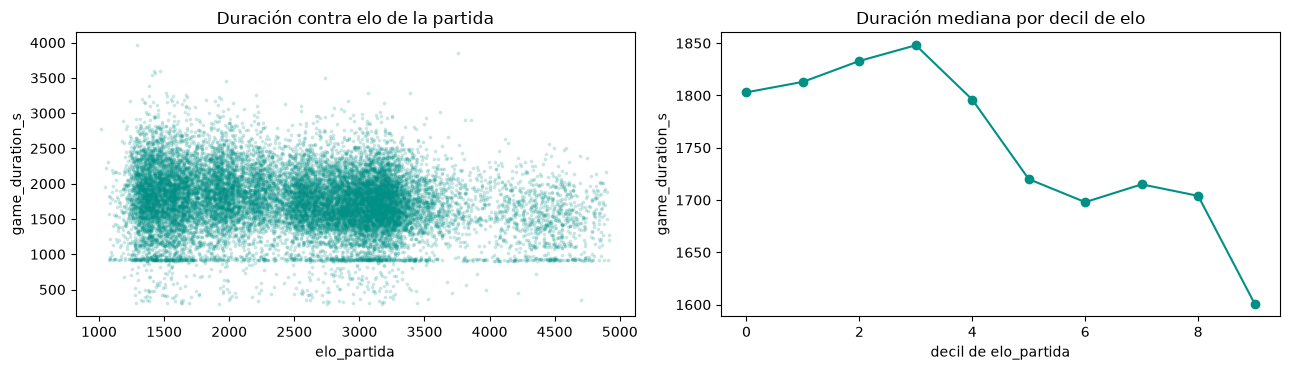

In [47]:
# La nube completa, y la duración mediana por decil de elo
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].scatter(df["elo_partida"], dur, s=3, alpha=.15, color=TEAL)
axes[0].set_title("Duración contra elo de la partida")
axes[0].set_xlabel("elo_partida")
axes[0].set_ylabel("game_duration_s")
deciles = pd.qcut(df["elo_partida"], 10, labels=False)
dur.groupby(deciles).median().plot(marker="o", color=TEAL, ax=axes[1])
axes[1].set_title("Duración mediana por decil de elo")
axes[1].set_xlabel("decil de elo_partida")
axes[1].set_ylabel("game_duration_s")
plt.tight_layout()
plt.show()

**Qué se ve.** La nube es una banda horizontal: a cualquier elo hay partidas de
20 y de 40 minutos. El panel de la derecha, que promedia el ruido, sí muestra
una pendiente descendente, y conviene leerla con cuidado en dos sentidos.
Primero, **no es monótona**: sube hasta el cuarto decil, en 1.848 segundos, y
recién ahí baja. Segundo, hay que mirar la escala del eje: entre el primer decil
y el último hay **202 segundos**, tres minutos y medio a lo largo de *todo* el
rango de elo del dataset, de 1.803 a 1.601. Eso es el −0,161 dibujado: una
tendencia real, chica y sucia.

Como el resultado es rojo, la hipótesis está cerrada. Lo que sigue **no es un
movimiento** —rojo no habilita movimientos— sino la demostración de por qué
insistir acá sería cazar resultados, y de paso la respuesta a la pregunta que
cualquiera haría: *¿y si el servidor está tapando el efecto?*

In [48]:
# Lo que pasaría si insistiéramos: la misma medida dentro de cada servidor
pd.DataFrame({pl: {**asociacion(g["elo_partida"], g["game_duration_s"]),
                   "n": len(g),
                   "zona": semaforo(asociacion(g["elo_partida"],
                                               g["game_duration_s"])["pearson"],
                                    "correlacion")}
              for pl, g in df.groupby("plataforma")}).T

,pearson,spearman,brecha,n,zona
BR1,-0.023,-0.014,0.009,3333,rojo
EUW1,-0.077,-0.088,-0.011,2950,rojo
KR,-0.254,-0.221,0.034,3430,amarillo
LA1,-0.089,-0.063,0.026,3355,rojo
LA2,-0.124,-0.085,0.039,3066,rojo
NA1,-0.014,0.006,0.02,3011,rojo


In [49]:
# La misma pregunta, pero comparando los promedios de los seis servidores
promedios = df.groupby("plataforma").agg(elo=("elo_partida", "mean"),
                                         duracion=("game_duration_s", "mean"))
r6 = promedios["elo"].corr(promedios["duracion"])
promedios.round(1).style.set_caption(
    f"correlación entre estas 6 filas: {r6:.4f}  ->  {semaforo(r6, 'correlacion')}")

,elo,duracion
plataforma,,
BR1,3036.000000,1687.000000
EUW1,2584.600000,1743.400000
KR,2254.100000,1688.600000
LA1,3231.200000,1722.100000
LA2,2178.500000,1837.000000
NA1,1627.300000,1825.700000


Controlar el servidor **no rescata nada**: cinco de los seis siguen en rojo, y
el único que asoma al amarillo es KR con −0,254. Un movimiento que no mejora el
resultado es información: dice que el servidor no estaba tapando el efecto.

La segunda celda es la trampa, y vale la pena verla porque es el error más
elegante que se puede cometer con estos datos. Si en vez de las 19.145 partidas
se comparan los **seis promedios** de servidor, la correlación da **−0,682**,
que es **verde**. Mismo dataset, dos respuestas opuestas. La de arriba es la que
vale: cada punto de la de abajo es un servidor entero, no una partida, así que
lo que mide es que los servidores donde la gente juega mejor tienden a tener
partidas más cortas *en promedio* — y con seis puntos eso puede ser casualidad.
Para predecir la duración de *una* partida, el número que manda es el −0,161.

**Qué hago con eso. Hipótesis refutada.** El elo no explica la duración, y no
va al informe como si lo hiciera. Pero la columna **no se descarta**: sigue
siendo la más asociada al objetivo de todo el dataset, así que entra a la
Unidad 3 como candidata débil, agregada por partida y no jugador por jugador.

## H2 · Las composiciones con más tanques alargan la partida

**Afirmación.** Cuantos más tanques hay en la partida, más dura: el tanque no
mata rápido y es difícil de matar, así que las peleas se estiran y cerrar una
base defendida por dos tanques lleva más tiempo.

**Qué espero ver.** Una relación positiva y clara. De las cuatro hipótesis de
dominio, ésta es la que más convencidos nos tenía: es lo que cualquiera que
juegue diría sin dudar.

**Por qué esta medida.** Es una asociación entre dos numéricas —los tanques
totales de la partida, de 0 a 10, y los segundos— así que van Pearson y
Spearman. La explicativa es discreta y con pocos valores, así que el gráfico
que corresponde no es una nube sino la mediana por valor.

In [50]:
# Los tanques de los dos equipos juntos contra la duración
h2 = asociacion(df["tanques_total"], dur)
pd.concat([h2, pd.Series({"zona": semaforo(h2["pearson"], "correlacion")})])

pearson    -0.008
spearman   -0.007
brecha      0.001
zona         rojo
dtype: object

**Resultado.** Pearson **−0,008**: **rojo**, y además con el signo al revés del
que anticipamos. Es el número más cercano a cero de las ocho fichas. La
hipótesis se refuta. Vamos al gráfico, que en este caso sí agrega algo: muestra
que no es que el efecto sea chico, es que no hay efecto en ninguna parte del
rango.

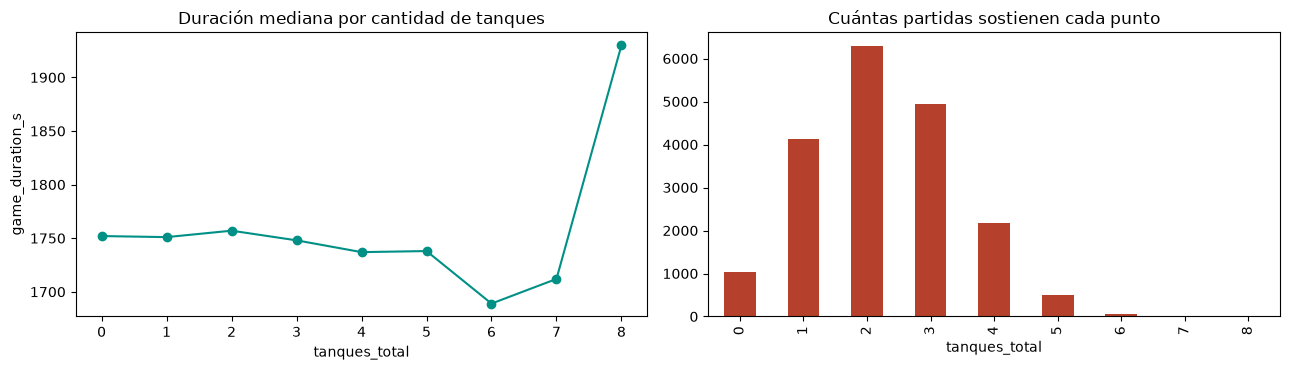

,partidas,mediana
tanques_total,,
0,1044,1752.0
1,4119,1751.0
2,6295,1757.0
3,4934,1748.0
4,2183,1737.0
5,507,1738.0
6,59,1689.0
7,3,1712.0
8,1,1930.0


In [51]:
# La duración mediana por cantidad de tanques, con el tamaño de cada grupo
tabla_h2 = df.groupby("tanques_total")["game_duration_s"] \
             .agg(partidas="size", mediana="median").round(1)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
tabla_h2["mediana"].plot(marker="o", color=TEAL, ax=axes[0])
axes[0].set_title("Duración mediana por cantidad de tanques")
axes[0].set_xlabel("tanques_total")
axes[0].set_ylabel("game_duration_s")
tabla_h2["partidas"].plot(kind="bar", color=LADRILLO, ax=axes[1])
axes[1].set_title("Cuántas partidas sostienen cada punto")
axes[1].set_xlabel("tanques_total")
plt.tight_layout()
plt.show()
tabla_h2

**Qué se ve.** La línea de la izquierda parece bajar al final, y el panel de la
derecha explica por qué no hay que creerle: **las partidas con 7 y con 8 tanques
son 3 y 1**. Sobre el rango donde hay datos de verdad —de 0 a 5 tanques, que
cubre el 99,7 % de las filas— las medianas son 1.752, 1.751, 1.757, 1.748,
1.737 y 1.738 segundos. Seis valores dentro de veinte segundos entre sí, sobre
una variable cuyo desvío estándar es 424.

Es el ejemplo de manual de por qué el gráfico solo no decide: si se dibujara
únicamente la línea de la izquierda, con el eje autoescalado, parecería que hay
una caída importante. El número dice que la variación entre grupos es ruido, y
el conteo dice de dónde sale la ilusión.

**Qué hago con eso. Hipótesis refutada**, y es la refutación más interesante de
las cuatro de dominio porque contradice lo que el grupo daba por sabido. La
conclusión sobre el juego: **la cantidad de tanques no dice nada sobre cuánto va
a durar una partida.** Las columnas `num_tanks` no se descartan por esto —van a
la tabla de candidatas junto con el resto de la composición— pero la hipótesis
de que ahí había señal queda enterrada con un número.

## H3 · Los campeones de rango largo son de armadura baja

**Afirmación.** El alcance de ataque y la armadura base son dos caras de la
misma decisión de diseño del juego: un campeón que pega de lejos paga esa
distancia siendo frágil, y uno que pelea de cerca la compensa con armadura. Si
eso es así, las dos columnas del bloque C que resumen esas dos cosas
—`avg_attackrange` y `total_base_armor`— están contando la misma historia con
el signo dado vuelta, y una de las dos sobra.

**Qué espero ver.** Una nube que baja hacia la derecha, y fuerte: es una
regularidad de diseño, no una tendencia estadística. Espero que sea la
asociación más fuerte del dataset entre dos columnas de composición, y que no
tenga curvatura — la relación entre las dos estadísticas tendría que ser recta.

**De dónde sale la afirmación**, que hay que declararlo porque la regla del
orden importa: **no del sentido común sino de la matriz de correlación de la
Sección 3**, que es de donde la fase 6 dice que tienen que salir las hipótesis
nuevas. Ahí apareció un −0,654 entre las dos columnas del equipo 1, sin que lo
estuviéramos buscando. Lo que la ficha agrega no es el hallazgo sino la
decisión: medirlo a nivel de **partida**, que es la unidad de análisis, y
resolver cuál de las dos columnas se va.

**Por qué esta medida.** Asociación entre dos numéricas, así que van Pearson y
Spearman, con la brecha como control de curvatura.

In [52]:
# El alcance medio de los 10 campeones contra la armadura base de la partida
h3 = asociacion(df["alcance_medio"], df["armadura_total"])
pd.concat([h3, pd.Series({"correlación": semaforo(h3["pearson"], "correlacion"),
                          "brecha": semaforo(h3["brecha"], "brecha")})])

pearson       -0.672
spearman      -0.653
brecha         0.019
correlación    verde
brecha          rojo
dtype: object

**Resultado.** Pearson **−0,672** y Spearman **−0,653**: **verde**, y es la
primera zona verde del notebook. La brecha es 0,019 —rojo—, así que la relación
es recta y no hay curvatura que buscar. **Verde termina la hipótesis**: no
corresponde ningún movimiento.

Conviene ver qué significa ese número en la escala de las dos columnas antes de
decidir cuál sale.

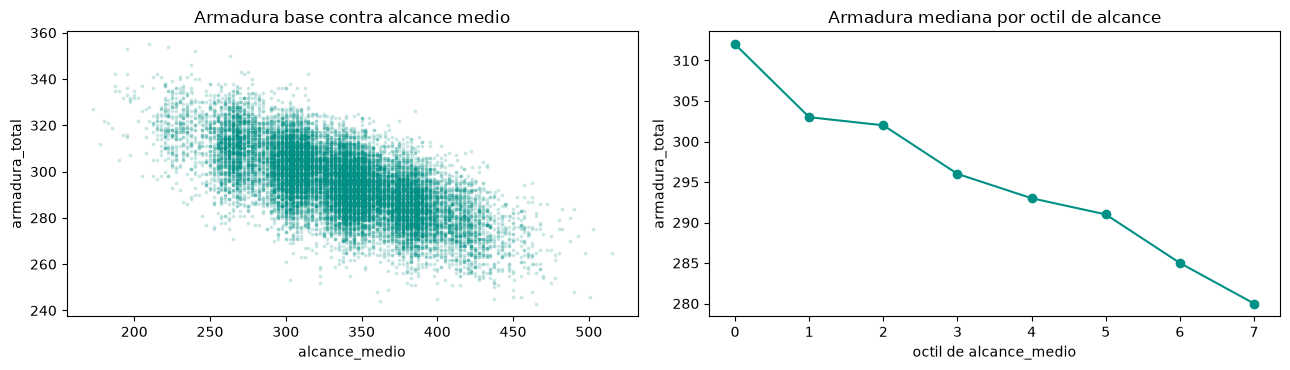

In [53]:
# La nube completa, y la armadura mediana por octil de alcance
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].scatter(df["alcance_medio"], df["armadura_total"], s=3, alpha=.15,
                color=TEAL)
axes[0].set_title("Armadura base contra alcance medio")
axes[0].set_xlabel("alcance_medio")
axes[0].set_ylabel("armadura_total")
octiles = pd.qcut(df["alcance_medio"], 8, labels=False)
df["armadura_total"].groupby(octiles).median().plot(marker="o", color=TEAL,
                                                    ax=axes[1])
axes[1].set_title("Armadura mediana por octil de alcance")
axes[1].set_xlabel("octil de alcance_medio")
axes[1].set_ylabel("armadura_total")
plt.tight_layout()
plt.show()

**Qué se ve.** La nube de la izquierda baja de forma limpia, y es la primera
del notebook que no es una banda horizontal: se le ve la pendiente sin
necesidad de promediar nada. El panel de la derecha la ordena: la armadura
mediana cae de **312 a 280** del primer al último octil de alcance,
monótonamente en los ocho. Son 32 puntos de armadura sobre una columna cuyo
desvío estándar es 14,5 — **más de dos desvíos de punta a punta**, que es la
diferencia con los efectos que veníamos midiendo contra la duración, donde la
caída completa no llegaba a un séptimo de desvío.

Antes de decidir cuál de las dos sale conviene medir el resto del bloque, porque
la armadura no está sola en esto.

In [54]:
# Las tres columnas de estadísticas base: entre sí, y contra el objetivo
pd.DataFrame({"entre sí": {"alcance ~ armadura": df["alcance_medio"].corr(df["armadura_total"]),
                           "armadura ~ hp": df["armadura_total"].corr(df["hp_total"]),
                           "alcance ~ hp": df["alcance_medio"].corr(df["hp_total"])},
              "cada una contra la duración": {"alcance ~ armadura": df["alcance_medio"].corr(dur),
                                              "armadura ~ hp": df["armadura_total"].corr(dur),
                                              "alcance ~ hp": df["hp_total"].corr(dur)}}).round(3)

,entre sí,cada una contra la duración
alcance ~ armadura,-0.672,0.054
armadura ~ hp,0.529,-0.066
alcance ~ hp,-0.477,-0.003


**Qué hago con eso. Hipótesis confirmada.** La conclusión sobre el juego:
**el alcance de ataque y la armadura base son la misma variable de diseño**, y
un campeón que pega de lejos es, de forma sistemática, un campeón de armadura
baja. Es la regularidad más fuerte que encontramos en todo el dataset.

Y la decisión sobre columnas, que es lo que se lleva la Entrega 3: de las dos
**sale `total_base_armor` y queda `avg_attackrange`**, por dos razones medidas
y ninguna estética. La primera es que la armadura es el centro de las dos
redundancias del bloque a la vez —0,672 con el alcance y 0,529 con la vida
base—, así que sacarla resuelve las dos de una vez y deja un par residual de
0,477 entre las que quedan, que es amarillo y queda declarado. La segunda es
que contra el objetivo las tres son igual de inútiles —0,054, −0,066 y −0,003,
las tres rojas—, así que la asociación con la duración **no sirve como criterio
de desempate** y no la usamos como si sirviera.

Son 2 columnas menos del bloque C, y el mismo argumento reaparece en H6 con
otro par.

## H4 · El elo y el winrate son la misma columna

**Afirmación.** `player_elo` y `player_winrate` se leen de dos lugares
distintos de la misma respuesta de League-V4: el elo sale de tier, división y
puntos de liga, y el winrate de la cuenta de victorias y derrotas. Pero miden
lo mismo, porque **la única forma de subir de división es ganar más de lo que
se pierde**. Si es así, darle las dos columnas a un modelo es darle la misma
información dos veces.

**Qué espero ver.** Una relación positiva y fuerte, pero no perfecta. El elo es
acumulado —es lo que el jugador construyó a lo largo de la temporada— y el
winrate es la tasa del momento, así que hay lugar para que difieran: un jugador
que acaba de subir de división tiene el elo arriba y el winrate cayendo. Espero
verde, no 0,95.

**Por qué esta medida.** Asociación entre dos numéricas, agregadas por partida
—el promedio de los diez jugadores en cada una—, porque la unidad de análisis
es la partida y no el jugador. Van Pearson y Spearman, con la brecha de
control.

In [55]:
# El elo medio de la partida contra el winrate medio de esos mismos 10 jugadores
h4 = asociacion(df["elo_partida"], df["wr_partida"])
pd.concat([h4, pd.Series({"correlación": semaforo(h4["pearson"], "correlacion"),
                          "brecha": semaforo(h4["brecha"], "brecha")})])

pearson        0.711
spearman       0.748
brecha         0.037
correlación    verde
brecha          rojo
dtype: object

**Resultado.** Pearson **0,711** y Spearman **0,748**: **verde**, y es la
asociación más fuerte del dataset entre dos columnas que vienen de la misma
fuente. La brecha es 0,037, rojo: la relación es recta. **Verde termina la
hipótesis.**

El número cae dentro de lo que esperábamos —fuerte pero no perfecto— y el
gráfico muestra de dónde sale el margen que falta para el 1.

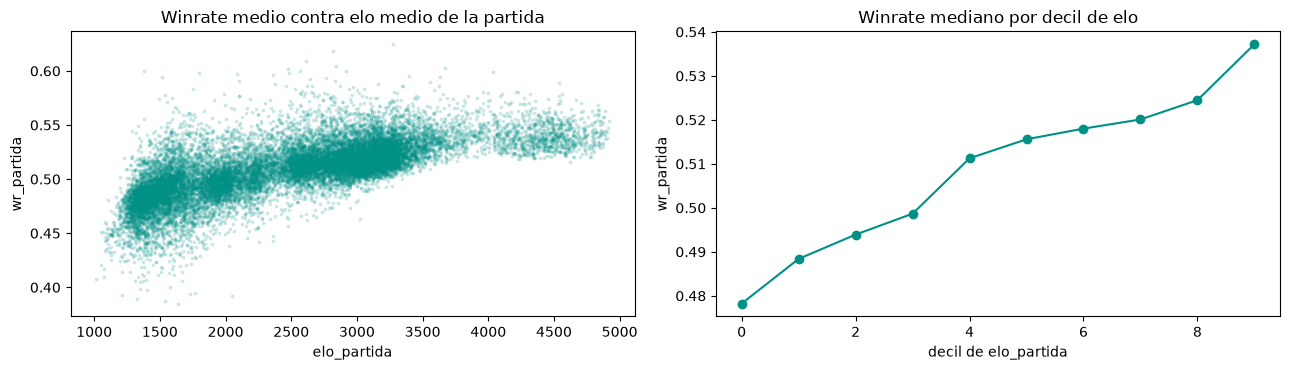

In [56]:
# La nube, y el winrate mediano por decil de elo
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].scatter(df["elo_partida"], df["wr_partida"], s=3, alpha=.15, color=TEAL)
axes[0].set_title("Winrate medio contra elo medio de la partida")
axes[0].set_xlabel("elo_partida")
axes[0].set_ylabel("wr_partida")
deciles_elo = pd.qcut(df["elo_partida"], 10, labels=False)
df["wr_partida"].groupby(deciles_elo).median().plot(marker="o", color=TEAL,
                                                    ax=axes[1])
axes[1].set_title("Winrate mediano por decil de elo")
axes[1].set_xlabel("decil de elo_partida")
axes[1].set_ylabel("wr_partida")
plt.tight_layout()
plt.show()

**Qué se ve.** La nube sube y tiene forma de banda inclinada, no de banda
horizontal: cada punto es una partida, y promediar diez jugadores suaviza el
ruido individual. El panel derecho la ordena: el winrate mediano sube de
**0,478 en el primer decil de elo a 0,537 en el décimo**, monótonamente en los
diez, sin una sola inversión.

Y ahí está el margen que falta para el 1: son **seis puntos de winrate** a lo
largo de todo el rango de elo del dataset, que va de 1.016 a 4.918. El winrate
de una cola clasificatoria vive apretado alrededor de 0,50 por construcción
—cada partida que alguien gana es una que otro pierde—, así que no puede
separarse tanto como el elo, que sí es acumulativo. Las dos columnas dicen lo
mismo; una lo dice con más rango que la otra.

**Qué hago con eso. Hipótesis confirmada, y salen diez columnas.** Las diez
`player_winrate` **salen** y las diez `player_elo` **quedan**, con tres razones,
ninguna de las cuales es que el winrate sea una mala idea:

1. **Redundancia medida:** 0,711, verde.
2. **El elo conserva más de la poca señal que hay contra el objetivo:** −0,161
   contra −0,120. Las dos rojas, pero la comparación entre las dos es lo que
   decide cuál se queda, y es el mismo criterio que usa H7.
3. **El reparo de fuga del winrate es peor.** Las dos columnas se leen días
   después de la partida, pero el winrate incluye *el resultado de esta misma
   partida* en sus `wins`/`losses`, mientras que el elo lo incluye diluido en
   toda la temporada. Sacar el winrate achica un problema que la Sección 9
   declara y no puede resolver.

## H5 · `count_flash` no aporta información y tiene que salir

**Afirmación.** `count_flash` es otra `count_smite`: casi todos los jugadores
llevan Destello, así que la columna es prácticamente constante y no puede
ayudar a distinguir una partida de otra.

**Qué espero ver.** Un reparto muy concentrado —la mayoría de los equipos con 5
de 5— y una asociación con la duración indistinguible de cero.

**Por qué estas medidas.** La afirmación tiene dos partes, así que hacen falta
dos números. Para «es casi constante», el peso del valor más frecuente. Para «no
aporta», la asociación con el objetivo: una columna puede variar poco y aun así
ser informativa, así que la varianza baja sola no alcanza para descartarla.

Es la primera de las cuatro fichas que no terminan en una conclusión sobre el
juego sino en una **decisión sobre una columna**.

In [57]:
# Cuán concentrado está el reparto, por equipo y por partida
pd.DataFrame({"por equipo (0 a 5 posibles)":
                  df["t1_count_flash"].value_counts(normalize=True),
              "por partida (0 a 10 posibles)":
                  df["flash_total"].value_counts(normalize=True)})     .reindex(range(11)).fillna(0).round(4)

,por equipo (0 a 5 posibles),por partida (0 a 10 posibles)
0,0.0000,0.0000
1,0.0000,0.0000
2,0.0003,0.0000
3,0.0101,0.0000
4,0.1513,0.0000
5,0.8382,0.0000
6,0.0000,0.0003
7,0.0000,0.0033
8,0.0000,0.0402
9,0.0000,0.2556


In [58]:
# ¿Y aporta algo, aunque varíe poco?
h5 = asociacion(df["flash_total"], dur)
pd.concat([h5, pd.Series({"zona": semaforo(h5["pearson"], "correlacion"),
                          "eta2": round(eta2(dur, df["flash_total"]), 4)})])

pearson     -0.014
spearman    -0.014
brecha         0.0
zona          rojo
eta2        0.0002
dtype: object

**Resultado.** Las dos partes se confirman. El **83,8 %** de los equipos lleva
los cinco Destellos posibles y el **70,1 %** de las partidas tiene 10 de 10; la
columna toma cuatro valores por equipo y el más común se come cinco sextos de
las filas. Y la asociación con la duración es **−0,014**, **rojo**, con η²
0,0002.

**Hipótesis confirmada, y la columna se descarta** — es la única de las ocho
donde confirmar la afirmación es la conclusión útil.

Antes de generalizar conviene un control, porque el argumento podría estar mal
atribuido: ¿la asociación es roja *porque* la columna casi no varía, o los
hechizos simplemente no explican la duración? Los otros dos contadores del
esquema sí varían, así que sirven de contraste.

In [59]:
# Los otros dos contadores de hechizos: varían mucho más, ¿aportan más?
pd.DataFrame({c: {"valor_modal": (df[f"t1_{c}"] + df[f"t2_{c}"])
                                 .value_counts(normalize=True).iloc[0].round(3),
                  "pearson": asociacion(df[f"t1_{c}"] + df[f"t2_{c}"], dur)["pearson"],
                  "zona": semaforo(asociacion(df[f"t1_{c}"] + df[f"t2_{c}"],
                                              dur)["pearson"], "correlacion")}
              for c in ["count_flash", "count_teleport", "count_ignite"]}).T

,valor_modal,pearson,zona
count_flash,0.701,-0.014,rojo
count_teleport,0.326,0.017,rojo
count_ignite,0.303,0.044,rojo


El contraste corrige el argumento. `count_teleport` y `count_ignite` tienen su
valor modal en el 33 % y el 30 % —varían muchísimo más que Destello— y aun así
dan **rojo**: 0,017 y 0,044. O sea que **los hechizos de invocador no explican
la duración, y la varianza baja de `count_flash` no es la causa del rojo, es un
motivo aparte para sacarla.** Los tres repartos, dibujados uno contra otro,
muestran de qué tamaño es la diferencia de varianza.

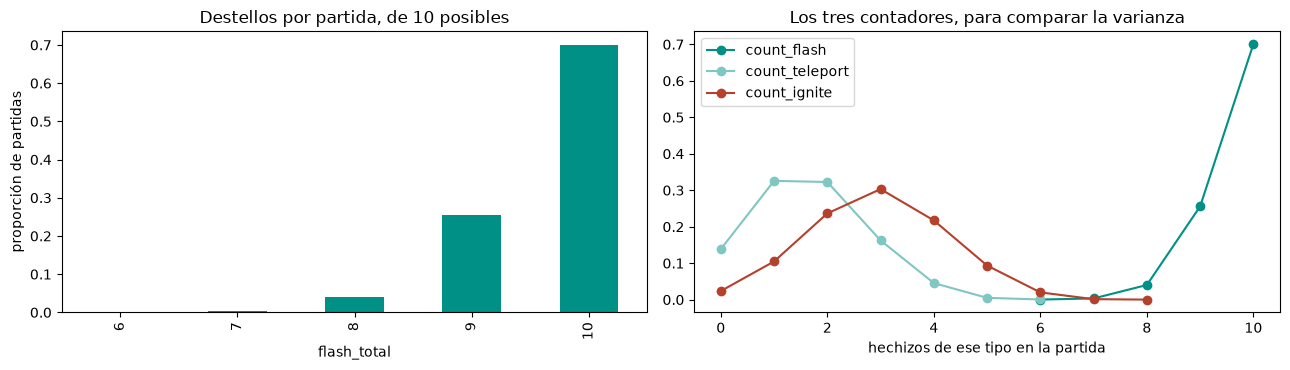

In [60]:
# El reparto de los tres contadores de hechizos, en la misma escala
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
df["flash_total"].value_counts(normalize=True).sort_index()     .plot(kind="bar", color=TEAL, ax=axes[0])
axes[0].set_title("Destellos por partida, de 10 posibles")
axes[0].set_xlabel("flash_total")
axes[0].set_ylabel("proporción de partidas")
for c, color in zip(["count_flash", "count_teleport", "count_ignite"],
                    [TEAL, "#7fc7c2", LADRILLO], strict=True):
    (df[f"t1_{c}"] + df[f"t2_{c}"]).value_counts(normalize=True).sort_index()         .plot(marker="o", color=color, ax=axes[1], label=c)
axes[1].set_title("Los tres contadores, para comparar la varianza")
axes[1].set_xlabel("hechizos de ese tipo en la partida")
axes[1].legend()
plt.tight_layout()
plt.show()

**Qué se ve.** El panel izquierdo es una sola barra con dos vecinas chicas: el
reparto de Destello está apoyado contra el techo de 10, que es el máximo posible.
En el derecho, la curva de `count_flash` es un pico y las de `count_teleport` y
`count_ignite` son campanas anchas que arrancan en 0 y llegan a 6 y a 8. Y hay
un detalle que la tabla ya mostraba: **`flash_total` nunca baja de 6**, o sea que
en las 19.145 partidas no hubo ni una con menos de seis Destellos. Ahí se ve por
qué la varianza baja es un argumento **aparte** del rojo: las tres dan rojo,
pero sólo una de las tres además no varía.

**Qué hago con eso.** `t1_count_flash` y `t2_count_flash` **salen** del conjunto
de features, con el mismo criterio con el que se sacó `count_smite` antes de la
Entrega 1, pero ahora con dos números en vez de un argumento sobre las reglas
del juego. `count_teleport` y `count_ignite` **se quedan**: son débiles, como
todo en este dataset, pero tienen varianza real y correlacionan −0,543 entre
ellos, lo que las vuelve interesantes como par.

## H6 · `avg_defense` es `num_tanks` escrito de otra forma

**Afirmación.** El bloque C trae dos formas de decir lo mismo sobre la
composición: contar cuántos de los cinco campeones tienen el tag `Tank` de Data
Dragon, y promediar la estadística `defense` de esos mismos cinco. Si el tag y
la estadística describen al mismo campeón, **saber cuántos tanques hay tiene
que explicar buena parte de la variación de la defensa media**, y entonces una
de las dos columnas sobra.

**Qué espero ver.** Que la defensa media suba de forma ordenada con la cantidad
de tanques, y que η² caiga en verde. Es casi una definición: si esto no diera
verde, el que estaría mal sería el tag de Data Dragon, y habría que revisar el
bloque C entero.

**Por qué esta medida.** La afirmación tiene forma de **comparación entre
varios grupos** —la defensa media difiere entre las partidas según cuántos
tanques tienen— y la medida que trae esa forma es **η²**, la razón de
correlación. `tanques_total` es un conteo de once niveles, de 0 a 10: se lee
como grupo, no como magnitud.

Es una elección que hay que poder defender, porque η² y Pearson no dan lo mismo
sobre estas dos columnas, y elegir la medida después de ver los dos números es
hacer trampa. Los dos se muestran abajo: la plantilla se fijó por la forma de la
afirmación, no por cuál de los dos convenía.

In [61]:
# Lo que la cantidad de tanques explica de la defensa media, con las dos medidas
h6 = pd.Series({"eta2": eta2(df["defensa_media"], df["tanques_total"]),
                "pearson": df["defensa_media"].corr(df["tanques_total"])}).round(3)
pd.concat([h6, pd.Series({"zona de eta2": semaforo(h6["eta2"], "eta2"),
                          "zona de pearson": semaforo(h6["pearson"], "correlacion")})])

eta2                  0.319
pearson               0.565
zona de eta2          verde
zona de pearson    amarillo
dtype: object

**Resultado.** η² **0,319**: **verde**. La cantidad de tanques explica el
**31,9 %** de la variación de la defensa media de la partida.

Pearson sobre las mismas dos columnas da **0,565**, que es amarillo, y la
diferencia entre los dos números no es un detalle técnico: **η² no exige que la
relación sea recta** —mide cuánto se separan las medias de los once grupos—
mientras que Pearson sólo captura la parte recta. Por eso la forma de la
afirmación manda: si la hipótesis se escribe como comparación entre grupos, la
medida es η², y el 0,565 queda como dato al costado, no como resultado.

**Verde termina la hipótesis.** Y antes de generalizar hace falta un control,
porque η² tiene una debilidad conocida: **sube con la cantidad de grupos**, así
que once niveles podrían estar capturando variación por puro azar.

In [62]:
# El control: la misma categoría de once niveles, contra otras numéricas
pd.DataFrame({"eta2": {
    "defensa media ~ tanques": eta2(df["defensa_media"], df["tanques_total"]),
    "magia media ~ magos": eta2(df["magia_media"], df["magos_total"]),
    "alcance medio ~ tanques": eta2(df["alcance_medio"], df["tanques_total"]),
    "duración ~ tanques": eta2(dur, df["tanques_total"])}}) \
    .assign(zona=lambda t: [semaforo(v, "eta2") for v in t["eta2"]]).round(3)

,eta2,zona
defensa media ~ tanques,0.319,verde
magia media ~ magos,0.310,verde
alcance medio ~ tanques,0.129,amarillo
duración ~ tanques,0.001,rojo


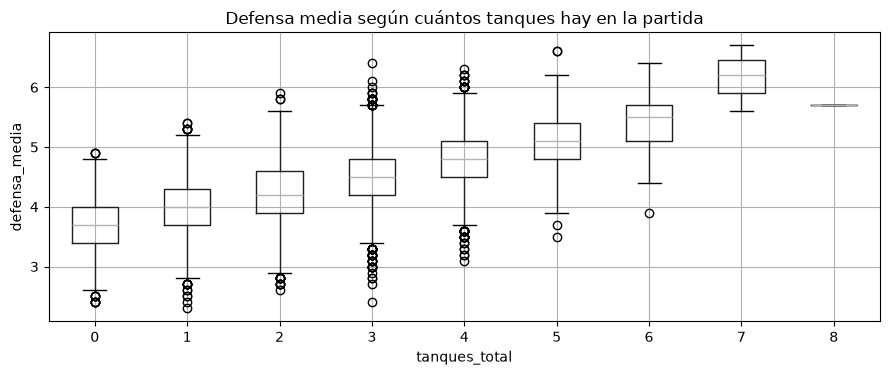

In [63]:
# Las once cajas: cuánto se separan de verdad los grupos
df.boxplot(column="defensa_media", by="tanques_total", figsize=(9, 4))
plt.title("Defensa media según cuántos tanques hay en la partida")
plt.suptitle("")
plt.xlabel("tanques_total")
plt.ylabel("defensa_media")
plt.tight_layout()
plt.show()

**Qué se ve.** Las cajas suben en escalera, de una mediana de 3,7 con cero
tanques a 5,1 con cinco, y cada grupo se solapa con su vecino pero no con los
que están a dos lugares. Es lo contrario del boxplot por servidor de la Sección
3, donde las seis cajas se pisaban casi por completo: ahí η² daba 0,020 y acá
da 0,319, y la diferencia se ve sin leer el número.

El control descarta la objeción del η² inflado. La **misma** categoría de once
niveles, aplicada a la duración, da **0,001** —rojo, trescientas veces menos—
y aplicada al alcance medio da 0,129, amarillo. Si η² estuviera
midiendo el azar de tener muchos grupos, esas tres cifras serían parecidas. No
lo son: η² es alto sólo cuando la categoría de verdad describe a la numérica.

Y el argumento se generaliza: **`magia_media` con `magos_total` da η² 0,310**,
también verde. Es el mismo mecanismo con otro par.

**Qué hago con eso. Hipótesis confirmada.** `avg_defense` y `avg_magic`
**salen**, y quedan `num_tanks` y `num_mages`. El criterio de cuál de las dos se
va, en los dos pares, es el mismo y no es la fuerza contra el objetivo —las
cuatro son rojas—: **se queda la que se puede explicar en una frase.** «Cuántos
tanques hay en la partida» es una variable que un jugador entiende y que se
puede auditar campeón por campeón; «el promedio de la estadística `defense` de
Data Dragon» es un número que hereda una escala de 1 a 10 que Riot no documenta.
Entre dos columnas que miden lo mismo, se queda la interpretable.

Son 4 columnas más del bloque C que salen, sobre las 2 de H3.

## H7 · La maestría binarizada pierde el orden de magnitud

**Afirmación.** `is_main` es `champ_mastery_pts >= 50000`, un umbral que eligió
el grupo, y `mains_count` cuenta cuántos de los cinco jugadores del equipo lo
superan. Binarizar una variable continua tira información, pero la pregunta es
**cuánta**: si la bandera conserva casi todo lo que dice la continua, la
continua sobra y el esquema se simplifica; si no conserva casi nada, la que
sobra es la bandera.

**Qué espero ver.** Una relación positiva y fuerte entre el conteo de mains de
la partida y la maestría agregada de los diez jugadores. El umbral de 50.000 nos
parecía razonable cuando lo elegimos, así que esperábamos que la bandera
conservara casi todo: verde de entrada, sin movimientos.

**Por qué esta medida.** Asociación entre dos numéricas: el conteo de jugadores
en su campeón principal, de 0 a 10, contra la maestría agregada de la partida.
Van Pearson y Spearman, y acá **la brecha entre los dos es la casilla que más
importa**: la maestría por jugador tiene asimetría 4,80, así que si hay
curvatura la brecha la va a delatar, y el movimiento que correspondería sería
cambiar la escala.

In [64]:
# Qué tan exigente es el umbral que elegimos
pd.Series({"jugadores con is_main == 1":
               (df[im_cols] == 1).sum().sum() / celdas,
           "mediana de puntos de maestría": maestria.median(),
           "umbral elegido por el grupo": 50_000}).round(4)

jugadores con is_main == 1            0.6792
mediana de puntos de maestría    111880.0000
umbral elegido por el grupo       50000.0000
dtype: float64

In [65]:
# El conteo de mains contra la maestría agregada, en la escala original
h7 = asociacion(df["mains_total"], df["mastery_partida"])
pd.concat([h7, pd.Series({"correlación": semaforo(h7["pearson"], "correlacion"),
                          "brecha": semaforo(h7["brecha"], "brecha")})])

pearson           0.471
spearman          0.549
brecha            0.078
correlación    amarillo
brecha         amarillo
dtype: object

**Resultado parcial.** Pearson **0,471**, Spearman **0,549** y brecha
**0,078**: la correlación cae en **amarillo** y la brecha también. Amarillo es
el único color que habilita seguir, así que ésta es la única de las ocho fichas
que hace un movimiento.

Y el primer número explica por qué la bandera no arranca mejor: el umbral de
50.000 puntos marca como «principal» al **67,9 %** de los jugadores, cuando la
mediana del dataset es de 111.880 puntos. El umbral no separa a los
especialistas del resto: está por debajo de la mitad de la población, así que la
bandera se prende para dos de cada tres jugadores.

Antes de elegir el movimiento hay que mirar el gráfico, porque es el gráfico el
que decide cuál de los tres corresponde.

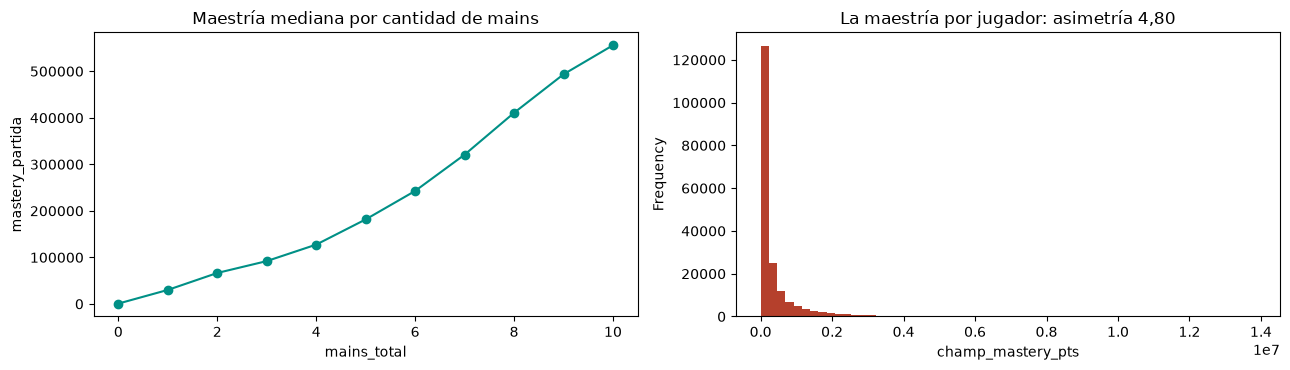

In [66]:
# Los dos paneles que eligen el movimiento: la forma de la curva y la de la cola
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
df["mastery_partida"].groupby(df["mains_total"]).median() \
    .plot(marker="o", color=TEAL, ax=axes[0])
axes[0].set_title("Maestría mediana por cantidad de mains")
axes[0].set_xlabel("mains_total")
axes[0].set_ylabel("mastery_partida")
maestria.plot.hist(bins=60, color=LADRILLO, ax=axes[1])
axes[1].set_title("La maestría por jugador: asimetría 4,80")
axes[1].set_xlabel("champ_mastery_pts")
plt.tight_layout()
plt.show()

**Qué se ve.** El panel izquierdo sube, pero no como una recta: se despega
recién en la mitad derecha y el último punto salta. El derecho explica por qué:
la maestría por jugador es una cola larguísima apoyada contra el cero, con casos
de trece millones de puntos. Cuando se promedian diez jugadores, **un solo
*one-trick* mueve el promedio de la partida entera**, y el promedio deja de
representar a los diez.

Es exactamente el cuadro que la cátedra describe para el tercer movimiento, y la
brecha amarilla ya lo había anticipado antes de dibujar nada.

**Movimiento 1: cambiar la escala.** El logaritmo, pero aplicado **donde
corresponde**, y ese detalle es la mitad del movimiento. `mains_count` se
construye jugador por jugador —cada uno aporta 1 o 0 según su propia maestría— y
recién después se suma. La continua comparable, entonces, es la que también se
transforma jugador por jugador y recién después se promedia. Tomar el logaritmo
del promedio no es lo mismo: el promedio crudo ya quedó dominado por los
*one-tricks* antes de que el logaritmo llegue. Las dos versiones se miden abajo,
para no tener que creerlo.

In [67]:
# Las tres formas de agregar la misma columna, contra el mismo conteo de mains
pd.DataFrame({
    "promedio de la maestría (original)": asociacion(df["mains_total"], df["mastery_partida"]),
    "logaritmo del promedio": asociacion(df["mains_total"], np.log1p(df["mastery_partida"])),
    "promedio del logaritmo por jugador": asociacion(df["mains_total"], df["logmastery_partida"])}).T \
    .assign(zona=lambda t: [semaforo(v, "correlacion") for v in t["pearson"]])

,pearson,spearman,brecha,zona
promedio de la maestría (original),0.471,0.549,0.078,amarillo
logaritmo del promedio,0.582,0.549,-0.033,amarillo
promedio del logaritmo por jugador,0.769,0.829,0.060,verde


**Resultado tras el movimiento.** Pearson **0,769** y Spearman **0,829**:
**verde**. La hipótesis se cierra con uno solo de los dos movimientos que
permite el tope.

Y la fila del medio es la que justifica haber sido cuidadosos con *dónde* se
aplica la escala: el logaritmo del promedio llega a **0,582**, que sigue siendo
amarillo. El mismo movimiento, aplicado en el lugar equivocado, no habría
alcanzado para cerrar la ficha. No es una sutileza de notación: es la diferencia
entre transformar a los diez jugadores y transformar un número que ya los
aplastó.

**Qué hago con eso. Hipótesis confirmada, y salen doce columnas.** Los diez
`is_main` y los dos `mains_count` **salen**: con la escala correcta la continua
y la bandera coinciden en 0,769, y de las dos la que tira información es la
bandera, porque nace de un umbral que elegimos nosotros y que el primer número
de la ficha muestra mal elegido. `champ_mastery_pts` **queda**, agregada por
partida y **en logaritmo aplicado por jugador antes de promediar**, que es la
forma que esta ficha midió y no otra.

Con una salvedad que conviene decir antes de que la pregunten: el promedio del
logaritmo tiene asimetría −3,88, porque las 22 partidas donde nadie llega al
umbral arrastran los ceros de `champ_mastery_pts` —jugadores que nunca tocaron
ese campeón— y `log1p(0)` vale 0. Son 22 filas de 19.145 y no mueven el
Spearman, que es de rangos, pero si la columna entra a un modelo sensible a las
colas hay que tratarlas.

Y queda una recomendación para la Entrega 3 que no es una columna sino un
criterio: si alguna vez hace falta una bandera de especialista, **el umbral no
lo elige el grupo a ojo, lo elige el dato** — por ejemplo el percentil 90 de
maestría, que en este dataset es 1.011.698 puntos y no 50.000.

## H8 · La partición t1/t2 duplica la información

**Afirmación.** `t1` y `t2` son los `teamId` 100 y 200, que Riot asigna sin
ningún criterio: no hay un equipo «local» ni uno «favorito». Entonces
`t1_num_tanks` y `t2_num_tanks` tienen que relacionarse con la duración de la
misma manera, y las 34 columnas del bloque C son en realidad 17 columnas
repetidas dos veces.

**Qué espero ver.** Que la correlación de cada agregado con el objetivo sea
prácticamente la misma para los dos equipos. Y espero algo más: que la **suma**
de los dos equipos correlacione mejor que cada mitad, porque duplica la cantidad
de información que resume sin agregar ruido.

**Por qué esta medida.** Asociación, aplicada cuatro veces a cada agregado: la
mitad de `t1`, la de `t2`, la suma y la diferencia absoluta. El número que
decide es **la diferencia entre las dos primeras correlaciones**, leída en la
escala de la correlación. Acá el rojo confirma en vez de refutar: si la
diferencia entre las dos mitades cae en rojo, es porque son indistinguibles, y
eso es justamente lo que afirma la hipótesis.

In [68]:
# Cada agregado, medido cuatro veces contra el objetivo
h8 = pd.DataFrame({
    a: {"t1": df[f"t1_{a}"].corr(dur), "t2": df[f"t2_{a}"].corr(dur),
        "suma": (df[f"t1_{a}"] + df[f"t2_{a}"]).corr(dur),
        "dif_abs": (df[f"t1_{a}"] - df[f"t2_{a}"]).abs().corr(dur)}
    for a in AGG}).T.round(3)
h8["|t1 - t2|"] = (h8["t1"] - h8["t2"]).abs()
h8["mejor"] = h8[["t1", "t2", "suma", "dif_abs"]].abs().idxmax(axis=1)
h8.sort_values("suma", key=abs, ascending=False)

,t1,t2,suma,dif_abs,|t1 - t2|,mejor
num_mages,0.044,0.053,0.069,0.013,0.009,suma
total_base_armor,-0.040,-0.053,-0.066,0.008,0.013,suma
avg_magic,0.045,0.033,0.056,0.009,0.012,suma
num_fighters,-0.046,-0.032,-0.055,0.007,0.014,suma
avg_attackrange,0.035,0.043,0.054,-0.005,0.008,suma
count_ignite,0.035,0.029,0.044,0.022,0.006,suma
num_supports,0.035,0.024,0.041,0.030,0.011,suma
avg_attack,-0.026,-0.020,-0.033,0.016,0.006,suma
num_assassins,-0.030,-0.015,-0.032,-0.009,0.015,suma
avg_defense,-0.006,-0.034,-0.029,0.019,0.028,t2


In [69]:
# Los dos números que deciden
pd.Series({"|t1 - t2| promedio": h8["|t1 - t2|"].mean().round(4),
           "|t1 - t2| máximo": h8["|t1 - t2|"].max().round(4),
           "zona del máximo": semaforo(h8["|t1 - t2|"].max(), "correlacion"),
           "agregados donde la suma es la mejor de las cuatro":
               int((h8["mejor"] == "suma").sum()),
           "de un total de": len(AGG)})

|t1 - t2| promedio                                   0.0126
|t1 - t2| máximo                                      0.028
zona del máximo                                        rojo
agregados donde la suma es la mejor de las cuatro        11
de un total de                                           17
dtype: object

**Resultado.** Las dos partes de la afirmación se confirman.

La diferencia entre la correlación de `t1` y la de `t2` es en promedio de
**0,0126** y como máximo de **0,028** —en `avg_defense`—, siete veces por debajo
del corte del rojo. Las dos mitades del bloque C son indistinguibles frente al objetivo, tal
como tenía que pasar si los rótulos son arbitrarios. Es el único lugar del
notebook donde el rojo es una buena noticia: **rojo acá significa «no hay
diferencia», y la hipótesis afirmaba que no debía haberla.**

Y la suma es la mejor de las cuatro formas en **11 de los 17** agregados, con
mejoras consistentes: `num_mages` pasa de 0,044 y 0,053 por separado a **0,069**
sumado, `total_base_armor` de −0,040 y −0,053 a **−0,066**, `avg_magic` de 0,045
y 0,033 a **0,056**. No es magia: sumar los dos equipos duplica el tamaño de la
muestra que resume cada número y cancela parte del ruido de cada mitad.

In [70]:
# Por qué la suma funciona: las composiciones de los dos equipos son independientes
pd.Series({a: df[f"t1_{a}"].corr(df[f"t2_{a}"]) for a in AGG}) \
    .sort_values(key=abs, ascending=False).head(5).round(3)

mains_count        0.176
count_teleport     0.067
count_ignite       0.052
avg_attackrange    0.038
num_marksmen       0.028
dtype: float64

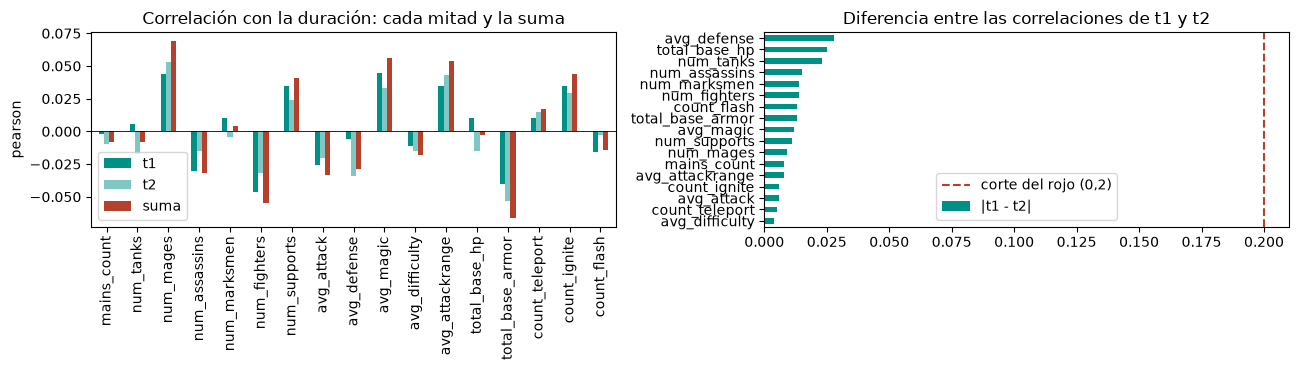

In [71]:
# El mismo agregado, medido de las cuatro formas
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
h8[["t1", "t2", "suma"]].plot(kind="bar", ax=axes[0],
                              color=[TEAL, "#7fc7c2", LADRILLO])
axes[0].set_title("Correlación con la duración: cada mitad y la suma")
axes[0].axhline(0, color="black", linewidth=.6)
axes[0].set_ylabel("pearson")
axes[0].tick_params(axis="x", rotation=90)
h8["|t1 - t2|"].sort_values().plot(kind="barh", color=TEAL, ax=axes[1])
axes[1].set_title("Diferencia entre las correlaciones de t1 y t2")
axes[1].axvline(0.2, color=LADRILLO, linestyle="--",
                label="corte del rojo (0,2)")
axes[1].legend()
plt.tight_layout()
plt.show()

**Qué se ve.** En el panel izquierdo las dos barras claras de cada agregado
tienen casi la misma altura y el mismo signo —ahí está el «son indistinguibles»—
y la barra ladrillo, la suma, casi siempre las supera a las dos. En el derecho,
las 17 diferencias contra el corte del rojo dibujado en 0,2: ninguna llega ni a
la séptima parte.

La celda del medio explica el mecanismo: la correlación entre `t1_X` y `t2_X` es
prácticamente nula para todo —el máximo es `mains_count` con 0,176— así que las
composiciones de los dos equipos son independientes entre sí. Sumar dos medidas
independientes del mismo fenómeno es exactamente cuándo promediar ayuda.

**Qué hago con eso. Hipótesis confirmada, y es la ficha que más cambia la
Entrega 3.** Los 34 agregados del bloque C **se colapsan en 17 sumas**, más la
diferencia absoluta en los dos casos donde fue la mejor de las cuatro
(`mains_count` y `num_marksmen`).

La aritmética final del bloque C hay que hacerla junto con las otras cuatro
fichas que sacan columnas, porque se pisan: de los 17 agregados salen cinco por
su cuenta —`mains_count` por H7, `avg_defense` y `avg_magic` por H6,
`total_base_armor` por H3 y `count_flash` por H5—, así que **las 34 columnas
quedan en 24, y esta ficha las colapsa en 12 sumas**. De `num_marksmen` se
conserva además la diferencia absoluta, que fue la mejor de sus cuatro formas.
El modelo arranca con poco más de un tercio del ancho original en ese bloque, y
con la interpretación más limpia: «cuántos magos hay en la partida» es una
variable del juego, «cuántos magos tiene el equipo al que Riot le puso el número
100» no lo es.

El mismo argumento se aplica al bloque B, que tiene el mismo problema
multiplicado por cinco, y ahí queda como recomendación: las 100 columnas de
jugador piden agregarse por partida antes de entrar a un modelo.

# Sección 9 · Las dos tablas

### El resumen de las ocho fichas

In [72]:
# Las ocho, con la trayectoria del número y la decisión a la que llegó cada una
pd.DataFrame(
    [("H1 a más elo, partidas más cortas", "responder", "asociación",
      "pearson -0,161 (por servidor: -0,014 a -0,254)", "rojo",
      "refutada; elo_partida entra igual, es la más fuerte"),
     ("H2 más tanques, partida más larga", "responder", "asociación",
      "pearson -0,008", "rojo",
      "refutada; contradice lo que el grupo daba por sabido"),
     ("H3 rango largo, armadura baja", "responder", "asociación",
      "pearson -0,672 (mediana 312 -> 280)", "verde",
      "confirmada: total_base_armor sale (2 columnas)"),
     ("H4 el elo y el winrate son lo mismo", "predecir", "asociación",
      "pearson 0,711 (winrate 0,478 -> 0,537)", "verde",
      "confirmada: player_winrate sale (10 columnas)"),
     ("H5 count_flash no aporta", "predecir", "asociación",
      "modal 0,838 y pearson -0,014", "rojo",
      "confirmada: count_flash sale (2 columnas)"),
     ("H6 avg_defense es num_tanks", "predecir", "comparación",
      "eta2 0,319 (magia/magos 0,310)", "verde",
      "confirmada: avg_defense y avg_magic salen (4 columnas)"),
     ("H7 la maestría binarizada pierde", "predecir", "asociación",
      "0,471 -> 0,769 (movimiento: escala)", "amarillo -> verde",
      "confirmada: is_main y mains_count salen (12 columnas)"),
     ("H8 la partición t1/t2 duplica", "predecir", "asociación",
      "|t1-t2| 0,013 y la suma gana en 11 de 17", "rojo",
      "confirmada: 34 -> 17 sumas, y 12 tras los otros recortes")],
    columns=["hipótesis", "pregunta", "plantilla", "medida", "zona", "decisión"])

,hipótesis,pregunta,plantilla,medida,zona,decisión
0,"H1 a más elo, partidas más cortas",responder,asociación,"pearson -0,161 (por servidor: -0,014 a -0,254)",rojo,"refutada; elo_partida entra igual, es la más f..."
1,"H2 más tanques, partida más larga",responder,asociación,"pearson -0,008",rojo,refutada; contradice lo que el grupo daba por ...
2,"H3 rango largo, armadura baja",responder,asociación,"pearson -0,672 (mediana 312 -> 280)",verde,confirmada: total_base_armor sale (2 columnas)
3,H4 el elo y el winrate son lo mismo,predecir,asociación,"pearson 0,711 (winrate 0,478 -> 0,537)",verde,confirmada: player_winrate sale (10 columnas)
4,H5 count_flash no aporta,predecir,asociación,"modal 0,838 y pearson -0,014",rojo,confirmada: count_flash sale (2 columnas)
5,H6 avg_defense es num_tanks,predecir,comparación,"eta2 0,319 (magia/magos 0,310)",verde,confirmada: avg_defense y avg_magic salen (4 c...
6,H7 la maestría binarizada pierde,predecir,asociación,"0,471 -> 0,769 (movimiento: escala)",amarillo -> verde,confirmada: is_main y mains_count salen (12 co...
7,H8 la partición t1/t2 duplica,predecir,asociación,"|t1-t2| 0,013 y la suma gana en 11 de 17",rojo,"confirmada: 34 -> 17 sumas, y 12 tras los otro..."


Dos refutadas y seis confirmadas, ninguna inconclusa. **Cuatro terminaron en
verde y cuatro en rojo**, y el corte entre los dos grupos es el hallazgo del
notebook, no una casualidad del reparto:

| | Contra qué se mide | Zona |
|---|---|---|
| H1, H2 | una columna contra **la duración** | rojo: no hay efecto |
| H5 | una columna contra la duración, y su propia varianza | rojo: la afirmación decía que no habría |
| H8 | una mitad del bloque C contra la otra | rojo: la afirmación decía que serían indistinguibles |
| **H3, H4, H6, H7** | **una columna contra otra columna** | **verde** |

Ninguna de las cuatro verdes mide contra el objetivo, y eso hay que decirlo
antes de que lo pregunten: **el verde no significa que hayamos encontrado una
feature buena.** Significa que encontramos columnas que se duplican entre sí, y
esa es una decisión de modelado tan concreta como la otra — saca 28 columnas del
dataset con un número detrás de cada una.

Una sola ficha usó un movimiento, H7, y es la única que cayó en amarillo. Las
otras siete terminaron en verde o en rojo, que son los dos colores que cierran.
Las dos veces que igual se midió algo más —el servidor en H1 y el control de η²
en H6— están escritas como lo que son: verificaciones de una objeción previsible,
no intentos de rescatar un resultado.

### El hallazgo que atraviesa las ocho

**Ninguna columna de condiciones iniciales predice la duración de la partida.**
El ranking completo, ordenado por fuerza, no llega a un tercio del corte más
bajo del semáforo.

In [73]:
# El ranking completo de candidatas contra el objetivo
candidatas = ["elo_partida", "wr_partida", "desbalance_elo", "mastery_partida",
              "logmastery_partida", "mains_total", "tanques_total", "magos_total",
              "flash_total", "alcance_medio", "defensa_media", "magia_media",
              "armadura_total", "hp_total", "roles_inferidos"] \
             + [f"{e}_{a}" for e in EQUIPOS for a in AGG]
ranking = pd.Series({c: df[c].corr(dur) for c in candidatas}) \
            .sort_values(key=abs, ascending=False)
pd.DataFrame({"pearson": ranking.round(3),
              "zona": [semaforo(v, "correlacion") for v in ranking]}).head(10)

,pearson,zona
elo_partida,-0.161,rojo
wr_partida,-0.120,rojo
magos_total,0.069,rojo
armadura_total,-0.066,rojo
desbalance_elo,-0.064,rojo
magia_media,0.056,rojo
alcance_medio,0.054,rojo
t2_total_base_armor,-0.053,rojo
t2_num_mages,0.053,rojo
mastery_partida,-0.049,rojo


In [74]:
# Cuánta varianza del objetivo explicaría la mejor columna, sola
mejor = ranking.iloc[0]
pd.Series({"la mejor columna": ranking.index[0],
           "pearson": round(mejor, 4),
           "R2": round(mejor ** 2, 4),
           "varianza del objetivo que explica": f"{100 * mejor ** 2:.1f} %"})

la mejor columna                     elo_partida
pearson                                  -0.1608
R2                                        0.0258
varianza del objetivo que explica          2.6 %
dtype: object

**La mejor columna del dataset explica el 2,6 % de la varianza de la duración.**
Es el número más importante del notebook y hay que decirlo sin maquillarlo: a la
pregunta del proyecto, con estas features y medida columna por columna, la
respuesta por ahora es **no**.

Con dos precisiones que importan, porque marcan la diferencia entre un resultado
y una rendición:

- Pearson y Spearman miden asociación de **una columna a la vez** y de forma
  **monótona**. Que ninguna columna sola sirva no prueba que no haya señal en
  **combinaciones** de columnas ni en relaciones no monótonas. Eso no lo decide
  el análisis exploratorio: lo decide el modelo de la Unidad 3, y ahora sabe
  contra qué compararse.
- El techo no es cero. La media constante ya acierta bastante porque el objetivo
  es simétrico y concentrado, así que la Unidad 3 tiene un rival claro: **hay
  que ganarle a predecir 1.748 segundos siempre.**

Es, además, el tipo de hallazgo que la consigna quiere que aparezca ahora y no
en octubre.

### La bandera `es_unranked`: una decisión que se cerró sin ficha

La documentación del proyecto dejaba abierta una pregunta de esquema: si
convenía agregar una bandera `es_unranked` en vez de esconder el caso dentro del
1500 de elo. La Sección 4 midió cuántas partidas están afectadas —615, el 3,2 %—
y dejó pendiente si además *duran* distinto. Es una comparación entre dos
grupos, así que la medida es la separación estandarizada, y no necesita una
ficha entera para contestarse.

In [75]:
# Las partidas con jugadores imputados, contra el resto
con_imp = dur[df["jugadores_imputados"] >= 1]
sin_imp = dur[df["jugadores_imputados"] == 0]
s_imp = separacion(con_imp, sin_imp)
pd.Series({"partidas con al menos uno": len(con_imp),
           "partidas sin ninguno": len(sin_imp),
           "mediana con": con_imp.median(), "mediana sin": sin_imp.median(),
           "separación": round(s_imp, 3), "zona": semaforo(s_imp, "separacion")})

partidas con al menos uno       615
partidas sin ninguno          18530
mediana con                  1788.0
mediana sin                  1750.0
separación                    0.067
zona                           rojo
dtype: object

Separación **0,067**: **rojo**. Las 615 partidas con jugadores imputados duran
una mediana de 1.788 segundos contra 1.750 del resto, **38 segundos de
diferencia** sobre una variable cuyo desvío estándar es 424. Con separación por
debajo de 0,2 las dos distribuciones comparten más del 90 % de su área.

**La decisión: para predecir la duración no hace falta la bandera.** La
imputación con 1500 / 0,50 queda como está, con su justificación intacta, y
`jugadores_imputados` no entra como feature.

Con dos salvedades que van escritas al lado de la decisión. La primera es que el
proxy es imperfecto —lo dice la Sección 4— y si alguna vez se agregara la bandera
aguas arriba habría que medir esto de nuevo con el dato real; el pipeline ya
calcula `es_unranked` en `include/lol/riot.py` pero no lo escribe al CSV, así que
es una columna de una línea. La segunda es que esto vale **para este objetivo**:
si en la Unidad 4 se quisiera predecir otra cosa —quién gana, por ejemplo— la
bandera podría importar, y la conclusión habría que rehacerla.

### La tabla de columnas candidatas

Es el entregable que se lleva la Entrega 3. Una advertencia sobre el formato: la
consigna pide una fila por columna, y este dataset tiene 137 que son **quince
patrones repetidos** por cinco posiciones y dos equipos. Ciento treinta y siete
filas serían un catálogo ilegible, que es justamente lo que la consigna
critica. La tabla lleva **una fila por familia**, con la cantidad de columnas
que abarca declarada, y una fila aparte para cualquier columna cuya decisión se
aparte de la de su familia. Las 137 están cubiertas y la suma se verifica al
final.

In [76]:
# Una fila por familia de columnas. La última columna es el chequeo de fuga.
CANDIDATAS = [
    ("match_id", 1, "Identificador de la partida", "—",
     "Sale: es la clave, no una feature", "Sí"),
    ("plataforma (derivada)", 0, "Servidor donde se jugó, del prefijo de match_id",
     "rojo (eta2 0,020)", "Entra como categórica de control", "Sí"),
    ("roles_inferidos", 1, "Jugadores sin teamPosition, bandera de calidad",
     "rojo (vale 0 en el 99,91 %)",
     "Sale como feature; queda para filtrar filas dudosas", "Sí"),
    ("{t1,t2}_{5 pos}_champ_id", 10, "Código del campeón elegido",
     "rojo (eta2 <= 0,016)",
     "Entra sólo con codificación categórica, nunca como entero", "Sí"),
    ("{t1,t2}_{5 pos}_champ_name", 10, "Nombre del campeón",
     "rojo", "Sale: mapea 1 a 1 con champ_id, es la misma columna", "Sí"),
    ("{t1,t2}_{5 pos}_sum1 y _sum2", 20, "Códigos de los hechizos de invocador",
     "rojo", "Salen como enteros; su información ya está en los count_*", "Sí"),
    ("{t1,t2}_{5 pos}_rune_primary", 10, "Código del árbol de runas principal",
     "rojo", "Entra sólo one-hot, o sale por cardinalidad", "Sí"),
    ("{t1,t2}_{5 pos}_rune_sub", 10, "Código del árbol secundario, con 27 ceros",
     "rojo", "Sale; si entrara, primero hay que tratar los 27 ceros", "Sí"),
    ("{t1,t2}_{5 pos}_player_elo", 10, "Proxy de nivel construido por el grupo",
     "rojo (-0,161 agregado: la más fuerte)",
     "Entra agregada por partida (elo_partida y desbalance_elo)",
     "Sí, con salvedad: se lee después de la partida"),
    ("{t1,t2}_{5 pos}_player_winrate", 10, "Winrate en solo/dúo",
     "verde (0,711 con el elo)",
     "Sale por H4: duplica a player_elo, que conserva más señal",
     "Sí, con salvedad: incluye el resultado de esta partida"),
    ("{t1,t2}_{5 pos}_champ_mastery_pts", 10, "Puntos de maestría en ese campeón",
     "verde (0,769 con mains_total)",
     "Entra agregada, en logaritmo por jugador antes de promediar (H7)",
     "Sí, con salvedad: suma los puntos de esta partida"),
    ("{t1,t2}_{5 pos}_is_main", 10, "Maestría >= 50.000, umbral elegido a ojo",
     "verde (0,769 con la continua)",
     "Sale por H7: la binarización pierde el orden de magnitud", "Sí"),
    ("{t1,t2}_mains_count", 2, "Suma de los 5 is_main del equipo",
     "verde (0,769 con la continua)", "Sale por H7, junto con is_main", "Sí"),
    ("{t1,t2}_num_{6 roles}", 12, "Campeones del equipo con cada tag de rol",
     "rojo (máx. -0,046)", "Entran como suma t1+t2 por H8 (6 columnas)", "Sí"),
    ("{t1,t2}_avg_defense y _avg_magic", 4, "Promedio de defensa y magia base",
     "verde (eta2 0,319 y 0,310)",
     "Salen por H6: los duplican num_tanks y num_mages", "Sí"),
    ("{t1,t2}_avg_attack, _avg_difficulty y _avg_attackrange", 6,
     "Promedios de ataque, dificultad y alcance base",
     "rojo contra el objetivo (máx. 0,054)",
     "Entran como suma por H8 (3 columnas)", "Sí"),
    ("{t1,t2}_total_base_armor", 2, "Suma de la armadura base de los 5 campeones",
     "verde (-0,672 con el alcance)",
     "Sale por H3: es el centro de dos redundancias a la vez", "Sí"),
    ("{t1,t2}_total_base_hp", 2, "Suma de la vida base de los 5 campeones",
     "rojo (-0,003)", "Entra como suma; 0,477 con el alcance, declarado", "Sí"),
    ("{t1,t2}_count_teleport y _ignite", 4, "Cuántos de esos hechizos lleva el equipo",
     "rojo", "Entran como suma; correlacionan -0,543 entre sí (son excluyentes)",
     "Sí"),
    ("{t1,t2}_count_flash", 2, "Cuántos Destellos lleva el equipo",
     "rojo (modal 0,838)", "Sale por H5, como antes count_smite", "Sí"),
    ("jugadores_imputados (derivada)", 0, "Jugadores con elo y winrate imputados",
     "rojo (separación 0,067)",
     "No entra: no hace falta la bandera es_unranked", "Sí"),
    ("game_duration_s", 1, "Duración de la partida, en segundos", "—",
     "Es el objetivo, no una feature", "No: es lo que hay que predecir"),
]
tabla = pd.DataFrame(CANDIDATAS, columns=[
    "Columna", "N", "Qué mide", "Zona", "Decisión", "¿Existiría al predecir?"])
tabla.style.hide(axis="index")

Columna,N,Qué mide,Zona,Decisión,¿Existiría al predecir?
match_id,1,Identificador de la partida,—,"Sale: es la clave, no una feature",Sí
plataforma (derivada),0,"Servidor donde se jugó, del prefijo de match_id","rojo (eta2 0,020)",Entra como categórica de control,Sí
roles_inferidos,1,"Jugadores sin teamPosition, bandera de calidad","rojo (vale 0 en el 99,91 %)",Sale como feature; queda para filtrar filas dudosas,Sí
"{t1,t2}_{5 pos}_champ_id",10,Código del campeón elegido,"rojo (eta2 <= 0,016)","Entra sólo con codificación categórica, nunca como entero",Sí
"{t1,t2}_{5 pos}_champ_name",10,Nombre del campeón,rojo,"Sale: mapea 1 a 1 con champ_id, es la misma columna",Sí
"{t1,t2}_{5 pos}_sum1 y _sum2",20,Códigos de los hechizos de invocador,rojo,Salen como enteros; su información ya está en los count_*,Sí
"{t1,t2}_{5 pos}_rune_primary",10,Código del árbol de runas principal,rojo,"Entra sólo one-hot, o sale por cardinalidad",Sí
"{t1,t2}_{5 pos}_rune_sub",10,"Código del árbol secundario, con 27 ceros",rojo,"Sale; si entrara, primero hay que tratar los 27 ceros",Sí
"{t1,t2}_{5 pos}_player_elo",10,Proxy de nivel construido por el grupo,"rojo (-0,161 agregado: la más fuerte)",Entra agregada por partida (elo_partida y desbalance_elo),"Sí, con salvedad: se lee después de la partida"
"{t1,t2}_{5 pos}_player_winrate",10,Winrate en solo/dúo,"verde (0,711 con el elo)","Sale por H4: duplica a player_elo, que conserva más señal","Sí, con salvedad: incluye el resultado de esta partida"


In [77]:
# Las 137 columnas del esquema tienen que estar todas cubiertas
pd.Series({"columnas del esquema cubiertas por la tabla": tabla["N"].sum(),
           "columnas del esquema": len(ORIGINALES),
           "filas de la tabla": len(tabla),
           "filas sin chequeo de fuga": (tabla["¿Existiría al predecir?"] == "").sum()})

columnas del esquema cubiertas por la tabla    137
columnas del esquema                           137
filas de la tabla                               22
filas sin chequeo de fuga                        0
dtype: int64

### El chequeo de fuga, que es la columna que más caro se paga

Antes de darle una columna a un modelo hay que preguntarse si esa columna
existiría en el momento de predecir. Si la respuesta ya está adentro, no es una
feature: es la respuesta escrita de otra forma.

En este dataset el riesgo grueso está descartado **por diseño**, y conviene
decirlo con lo que *no* está: no hay kills, ni oro, ni torres, ni deltas por
minuto, ni resultado de la partida. El esquema se limitó a condiciones
iniciales, así que no hay ninguna columna que se complete después del hecho que
queremos predecir. No hay ninguna candidata a `motivo_de_la_baja`.

Pero hay dos reparos que no son fuga y que igual hay que declarar, porque son la
diferencia entre «esta columna existe al predecir» y «esta columna vale lo mismo
al predecir»:

**Uno. `player_elo`, `player_winrate` y `champ_mastery_pts` se leen después de la
partida.** El pipeline consulta League-V4 y Champion-Mastery-V4 cuando baja la
partida, que es días o semanas más tarde. Eso quiere decir que la victoria o la
derrota de *esta misma partida* ya está contada en los `wins`/`losses` del
winrate, y que los puntos que el jugador ganó en *esta misma partida* ya están
sumados en la maestría. No filtra la duración —saber que alguien ganó no dice
cuánto duró— pero **no es el valor que existiría al arrancar**. Puesto en
producción, el pipeline tendría que leer esas tres cosas antes del primer
minuto. El winrate es el más comprometido de los tres —cuenta el resultado de
esta partida como una victoria o una derrota entera, no diluida— y **ya sale
por H4**, así que ese reparo se achica solo. Los otros dos entran, con la
salvedad escrita, y con un pendiente: medir si el valor previo cambia el
resultado necesita un snapshot que no tenemos.

**Dos. La posición de cada jugador sale de `teamPosition`, que Riot completa al
cerrar la partida.** Todo el bloque B está organizado por carril, y ese carril
es una inferencia que Riot hace mirando la partida terminada. En producción la
asignación habría que tomarla de la selección de campeones, que la sabe antes de
empezar. El reparo es menor —en clasificatoria de draft los carriles se acuerdan
antes— y `roles_inferidos` dice que sólo 17 filas tuvieron el campo vacío, pero
la columna que estamos usando no es la que existiría al predecir.

### Qué quedó inconcluso, y qué haría falta para resolverlo

1. **Si la señal está en las combinaciones.** Medimos columna por columna y de
   forma monótona. Haría falta un modelo con interacciones —de los de la Unidad
   3— para saber si la duración se explica por cruces que ninguna correlación
   simple puede ver.
2. **Las 26 partidas con 9 o 10 jugadores imputados.** Sospechamos una tanda de
   consultas fallida a League-V4 y no un grupo de nueve jugadores sin clasificar,
   pero no lo verificamos: hace falta el bronce de la corrida grande, que está en
   la máquina de otro integrante.
3. **Si los valores previos a la partida cambian algo.** Los reparos de fuga
   del apartado anterior se resolverían leyendo el elo y la maestría antes del
   arranque, y eso requiere cambiar el pipeline y volver a recolectar.
4. **La composición de campeones.** Es la única dirección que mostró estructura
   clara —Brand y Teemo aparecen 1,35 veces más de lo que les toca en el cuartil
   de partidas largas, Kalista 0,61 veces— y quedó como candidata a novena ficha,
   sin resolver.

# Cierre

Ocho hipótesis, ocho decisiones. Seis confirmadas y dos refutadas, cuatro en
verde y cuatro en rojo. El corte entre los dos colores es el resultado de fondo
y conviene decirlo en una sola frase: **las condiciones iniciales de una partida
de League of Legends no dicen cuánto va a durar, pero sí se dicen mucho entre
ellas.** La columna más informativa de las 137 explica el 2,6 % de la variación
del objetivo; en cambio cuatro pares de columnas se duplican con fuerza medida
entre 0,672 y 0,769.

Lo que la Entrega 3 se lleva de acá no es una lista de features prometedoras,
porque no hay ninguna. Se lleva tres cosas concretas:

- **Un dataset bastante más angosto y con un número detrás de cada recorte.**
  Salen **40 columnas**: los diez `player_winrate` por H4, los diez `is_main` y
  los dos `mains_count` por H7, los cuatro `avg_defense` y `avg_magic` por H6,
  los dos `total_base_armor` por H3, los dos `count_flash` por H5 y los diez
  `champ_name` por mapear uno a uno con `champ_id`. De las 34 columnas de
  agregados de equipo quedan 24 después de esos recortes —doce agregados, dos
  veces cada uno— y H8 las colapsa en **12 sumas**.
- **Un objetivo caracterizado.** Simétrico, sin desbalance, sin necesidad de
  transformarse, truncado a izquierda en 300 segundos por decisión nuestra, y
  con un escalón de 714 partidas en los 900 segundos que ningún modelo suave va
  a reproducir.
- **Un rival contra el que medirse.** Predecir siempre 1.748 segundos. Si el
  modelo de la Unidad 3 no le gana con claridad, la respuesta a la pregunta del
  proyecto es negativa, y eso también es un resultado.